# EasyAE, Hydrophone, and MPD DC Combined Analysis

Uses a hydrophone LVM file, an AE WFS file (or the existing waveform CSV workflow), and the two native MPD DC exports: measured voltage and individual PD charge. Requirements and the acoustic analysis follow `EasyAE_Hydrophone_MPD_combined_analysis.ipynb`.

Run cells in order in your existing `ned3` kernel. First review the hydrophone trigger, which defines shared time zero; then align AE to the hydrophone using the early hammer hit. Optional acoustic overlap, hammer-hit removal, and manual plotting limits are retained. Load the two DC CSVs and review their common offset in the 2x2 combined figure. A positive offset moves both electrical sources later.

CSV elapsed timestamps retain their original difference: the first PD event is not reset to zero. Electrical data is capped at the later retained acoustic end when forced overlap is declined, or the shared end when accepted. Signed-log pulse charge retains positive and negative magnitudes, with logarithmic coloring for event counts and a printed minimum charge. All events in the displayed interval are used.

Saved acoustic figures and the optional acoustic PowerPoint summary retain the original workflow. The accepted DC combined figure uses a distinct `Hydrophone_AE_MPD_DC_PD_Combined` filename. If you revise trigger selection, reload/re-align AE and rerun subsequent cells; if you revise manual plotting bounds, rerun subsequent RMS, spectrogram, and plotting cells.

In [1]:
import pandas as pd
import math
import numpy as np
from numpy.fft import rfft, rfftfreq
from numpy.lib.stride_tricks import as_strided
import matplotlib as mpl
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.ticker import MaxNLocator, MultipleLocator, AutoMinorLocator
import matplotlib.animation as animation
import scipy
from scipy import stats
from scipy.signal import welch, stft, spectrogram, butter, sosfiltfilt, get_window
from scipy.stats import chi2
from scipy.optimize import curve_fit
from scipy.interpolate import interp1d
import os
from datetime import datetime, timedelta
import re
import pywt
import copy
import json
import hashlib
from tqdm import tqdm
import matplotlib.pyplot as plt
import pickle
from IPython.display import clear_output

# Requires the published 'decode-wfs' package. Install it with `pip install decode-wfs`.
from decode_wfs import load_continuous

mpl.rcParams['agg.path.chunksize'] = 10000000
from pathlib import Path

In [2]:
label_size=14
tick_size=12
figure_dpi=150

## Load LVM file

In [3]:
trigger_shifted = False
data_trimmed = False
ae_synced_on_peak = False
trigger_review_accepted = False

while True:
    filepath = input("Enter the absolute path to lvm file: ").strip().strip('"')
    if os.path.isfile(filepath) and filepath.endswith(".lvm"):
        break
    print("Invalid file. Try again.")

print(f"Using file: {filepath}")

# Set up output directory and save function for images
lvm_path = Path(filepath).expanduser().resolve()
img_dir = lvm_path.parent / "imgs"
img_dir.mkdir(exist_ok=True)

lvm_stem = lvm_path.stem

def add_ae_sync_note(fig):
    for text in list(fig.texts):
        if text.get_gid() == "ae_sync_note":
            text.remove()

    if ae_synced_on_peak:
        return

    note = fig.text(
        0.995,
        0.005,
        "AE not synchronized to hydrophone peak",
        ha="right",
        va="bottom",
        fontsize=7,
        color="firebrick",
        bbox={"facecolor": "white", "edgecolor": "firebrick", "alpha": 0.75, "boxstyle": "round,pad=0.15"},
    )
    note.set_gid("ae_sync_note")


def save_figure(fig, suffix, category, stem=lvm_stem, dpi=figure_dpi, includes_ae=False):
    if includes_ae:
        add_ae_sync_note(fig)

    category_dir = img_dir / category
    category_dir.mkdir(parents=True, exist_ok=True)

    ext = ".png"
    base_name = f"{stem}_{suffix}"
    out_path = category_dir / f"{base_name}{ext}"

    # Keep saved paths comfortably under common Windows path-length limits.
    max_path_len = 240
    if len(str(out_path)) > max_path_len:
        digest = hashlib.sha1(base_name.encode("utf-8")).hexdigest()[:8]
        max_name_len = max_path_len - len(str(category_dir)) - 1 - len(ext)
        truncated_len = max(16, max_name_len - len(digest) - 1)
        short_name = f"{base_name[:truncated_len].rstrip('_')}_{digest}"
        out_path = category_dir / f"{short_name}{ext}"
        print(f"Filename shortened for Windows path limit: {out_path.name}")

    fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
    print(f"Saved figure: {out_path}")
    return out_path


# Find the header line and parse column names
header_line = None
start_line = None
with open(filepath, "r") as f:
    for i, line in enumerate(f):
        if line.strip().startswith("X_Value"):
            header_line = line
            start_line = i + 1
            break

if start_line is None:
    raise ValueError("Couldn't find the 'X_Value' header line in the file.")

# Parse column names from header
col_names = [c.strip() for c in header_line.split(",")]

# Identify indices of the columns we care about
REQUIRED = ["X_Value", "Voltage"]          # adjust "Voltage" to match your actual header name
OPTIONAL = ["Trigger Voltage"]

wanted = REQUIRED + [c for c in OPTIONAL if c in col_names]
usecols = [col_names.index(c) for c in wanted]

# Load only the columns we want
lvm_data = np.loadtxt(filepath, delimiter=",", skiprows=start_line, usecols=usecols)
# Preserve file time so trigger review and zeroing can be rerun without compounding shifts.
lvm_time_raw = lvm_data[:, 0].copy()

# Build a dict for clean, name-based access
channels = {name: lvm_data[:, i] for i, name in enumerate(wanted)}

# Normalize signal
channels["Voltage"] -= channels["Voltage"].mean()

# Check if optional column was loaded
has_trigger = "Trigger Voltage" in channels
if has_trigger:
    print("Trigger Voltage column detected.")

hydrophone_sample_rate = 1 / np.mean(np.diff(channels["X_Value"]))
print(f"Estimated sampling frequency: {hydrophone_sample_rate:.2f} Hz")

# Preview
header = f"{'Row':<6} {'Time (s)':>14} {'Voltage (V)':>14}"
if has_trigger:
    header += f" {'Trigger (V)':>14}"
print(f"\n{header}")
print("-" * (36 + 15 * has_trigger))
for i in range(min(10, lvm_data.shape[0])):
    row = f"{i:<6} {channels['X_Value'][i]:>14.6f} {channels['Voltage'][i]:>14.6f}"
    if has_trigger:
        row += f" {channels['Trigger Voltage'][i]:>14.6f}"
    print(row)

def highpass_filter(signal, cutoff_hz, fs, order=4):
    sos = butter(order, cutoff_hz, btype='high', fs=fs, output='sos')
    return sosfiltfilt(sos, signal)

# High-pass filter to remove frequencies below a cutoff frequency
cutoff_freq = 60.0  # Hz
high_pass_lvm_data = lvm_data.copy()
high_pass_lvm_data[:, 1] = highpass_filter(lvm_data[:, 1], cutoff_freq, hydrophone_sample_rate)

Using file: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\PD-acoustic-EMPIRE_147.lvm
Trigger Voltage column detected.
Estimated sampling frequency: 12800.00 Hz

Row          Time (s)    Voltage (V)    Trigger (V)
---------------------------------------------------
0            0.000000      -0.040934      -0.002208
1            0.000078      -0.040753      -0.002211
2            0.000156      -0.040690      -0.002208
3            0.000234      -0.041043      -0.002099
4            0.000312      -0.041212      -0.002065
5            0.000391      -0.041223      -0.002080
6            0.000469      -0.041524      -0.002099
7            0.000547      -0.041437      -0.002189
8            0.000625      -0.041313      -0.002331
9            0.000703      -0.041415      -0.002358


## Detect and Review the Hydrophone Trigger

The trigger is the second measured channel (`Trigger Voltage`), after the hydrophone voltage; the first numeric column is time. The initial threshold is midway between the trigger baseline and positive pulse peak, with a 0.001 V minimum, to avoid weak noise crossings. The first sample above it is proposed automatically. Review the overview and detailed pulse view, adjust the threshold or enter a replacement **original LVM file time**, and enter `done` to accept.

If the trigger channel or automatic detection is unavailable, enter its known file time manually. After changing an accepted trigger, rerun the following time-zeroing cell and the AE loading/synchronization and downstream analysis cells.

Proposed trigger: original LVM time 20.435625 s (auto).


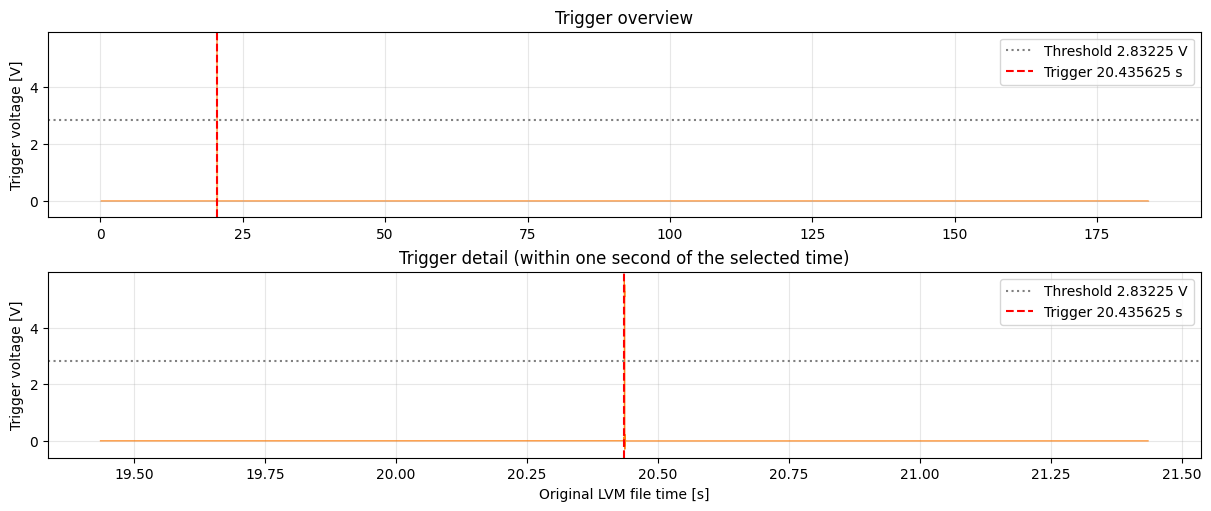

Accepted trigger: original LVM time 20.435625 s. This defines shared t = 0.


In [4]:
# Start midway between the trigger baseline and positive pulse peak to reject small noise crossings.
trigger_threshold = 0.001  # V fallback; the threshold remains editable during review.
if has_trigger:
    trigger_baseline = float(np.median(channels['Trigger Voltage']))
    trigger_peak_voltage = float(np.max(channels['Trigger Voltage']))
    trigger_threshold = max(trigger_threshold, trigger_baseline + 0.5 * (trigger_peak_voltage - trigger_baseline))
first_trigger_time = None
trigger_review_accepted = False
trigger_shifted = False
ae_synced_on_peak = False
data_trimmed = False
trigger_selection_mode = 'auto'


def detect_trigger_time(threshold):
    if not has_trigger:
        return None
    indices = np.flatnonzero(channels['Trigger Voltage'] > threshold)
    return float(lvm_time_raw[indices[0]]) if indices.size else None


def plot_trigger_review(selected_time, threshold, time_shift=0.0):
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), constrained_layout=True)
    times = lvm_time_raw - time_shift
    if has_trigger:
        signal = channels['Trigger Voltage']
        # A min/max envelope keeps narrow pulses visible in a bounded-size overview.
        step = max(1, len(times) // 5000)
        starts = np.arange(0, len(times), step)
        axes[0].fill_between(times[starts], np.minimum.reduceat(signal, starts),
                             np.maximum.reduceat(signal, starts), color='tab:orange', alpha=0.6)
        center = selected_time if selected_time is not None else float(lvm_time_raw[0])
        left = np.searchsorted(lvm_time_raw, center - 1.0)
        right = np.searchsorted(lvm_time_raw, center + 1.0, side='right')
        axes[1].plot(times[left:right], signal[left:right], color='tab:orange', linewidth=0.8)
        for ax in axes:
            ax.axhline(threshold, color='gray', linestyle=':', label=f'Threshold {threshold:g} V')
    else:
        for ax in axes:
            ax.text(0.5, 0.5, 'No Trigger Voltage channel: enter the known trigger file time.',
                    transform=ax.transAxes, ha='center', va='center')
        axes[0].set_xlim(times[0], times[-1])
    for ax in axes:
        if selected_time is not None:
            ax.axvline(selected_time - time_shift, color='red', linestyle='--',
                       label=f'Trigger {selected_time - time_shift:.6f} s')
        ax.set_ylabel('Trigger voltage [V]')
        ax.grid(alpha=0.3)
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(loc='upper right')
    axes[0].set_title('Trigger overview')
    axes[1].set_title('Trigger detail (within one second of the selected time)')
    axes[1].set_xlabel('Original LVM file time [s]' if time_shift == 0 else 'Time from accepted trigger [s]')
    return fig


trigger_status = ''
while True:
    if trigger_selection_mode == 'auto':
        first_trigger_time = detect_trigger_time(trigger_threshold)
    clear_output(wait=True)
    if trigger_status:
        print(trigger_status)
    if first_trigger_time is None:
        print('No trigger selected. Adjust the threshold or enter a known trigger file time.')
    else:
        print(f'Proposed trigger: original LVM time {first_trigger_time:.6f} s ({trigger_selection_mode}).')
    trigger_fig = plot_trigger_review(first_trigger_time, trigger_threshold)
    plt.show()
    response = input('Enter "done", "threshold V", "time seconds" (original LVM time), or "auto": ').strip()
    if response.lower() == 'done':
        if first_trigger_time is not None:
            trigger_review_accepted = True
            break
        trigger_status = 'Select a valid trigger time before entering done.'
    elif response.lower() == 'auto':
        trigger_selection_mode = 'auto'
        trigger_status = ''
    else:
        try:
            command, value = response.lower().split()
            value = float(value)
            if not np.isfinite(value):
                raise ValueError('The value must be finite.')
            if command == 'threshold':
                trigger_threshold = value
                trigger_selection_mode = 'auto'
            elif command == 'time':
                if not lvm_time_raw[0] <= value <= lvm_time_raw[-1]:
                    raise ValueError('The trigger time must lie inside the LVM recording.')
                first_trigger_time = value
                trigger_selection_mode = 'manual'
            else:
                raise ValueError('Use threshold or time followed by a number.')
            trigger_status = ''
        except ValueError as exc:
            trigger_status = f'Invalid entry: {exc}'
    plt.close(trigger_fig)

print(f'Accepted trigger: original LVM time {first_trigger_time:.6f} s. This defines shared t = 0.')

## Set Hydrophone Time Zero at the Accepted Trigger

Hydrophone time zero: original trigger at 20.435625 s.
Trigger-relative hydrophone range: -20.435625 to 163.564297 s.
First 10 trigger-referenced rows:
[[-2.04356250e+01 -4.09339309e-02 -2.20800000e-03]
 [-2.04355469e+01 -4.07529309e-02 -2.21100000e-03]
 [-2.04354690e+01 -4.06899309e-02 -2.20800000e-03]
 [-2.04353910e+01 -4.10429309e-02 -2.09900000e-03]
 [-2.04353130e+01 -4.12119309e-02 -2.06500000e-03]
 [-2.04352340e+01 -4.12229309e-02 -2.08000000e-03]
 [-2.04351560e+01 -4.15239309e-02 -2.09900000e-03]
 [-2.04350780e+01 -4.14369309e-02 -2.18900000e-03]
 [-2.04350000e+01 -4.13129309e-02 -2.33100000e-03]
 [-2.04349220e+01 -4.14149309e-02 -2.35800000e-03]]


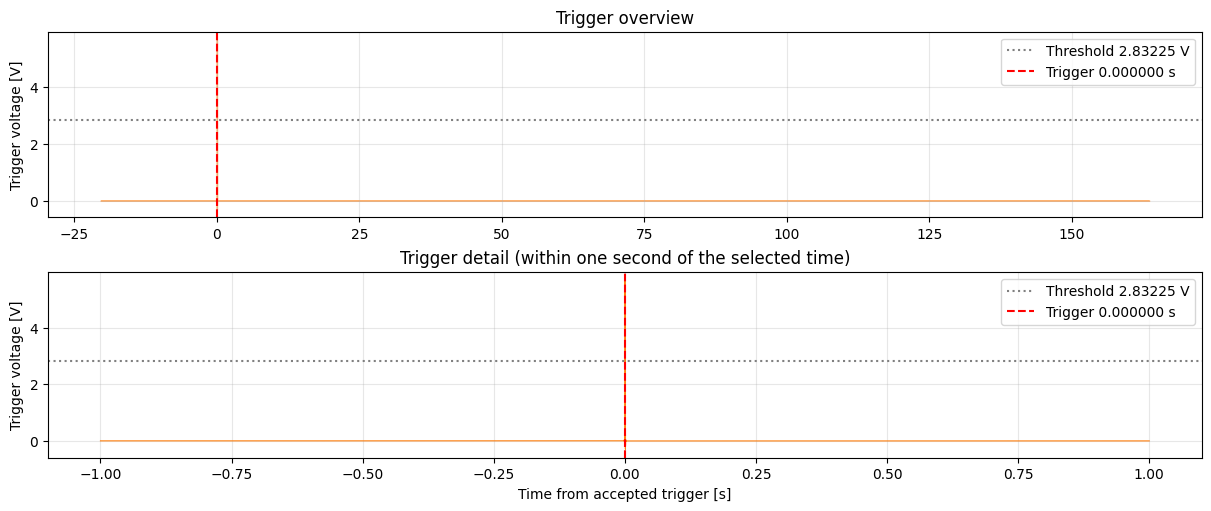

In [5]:
if not trigger_review_accepted or first_trigger_time is None:
    raise RuntimeError('Review and accept the hydrophone trigger first.')

# Rebuild from file time rather than subtracting from an already shifted timeline.
lvm_data[:, 0] = lvm_time_raw - first_trigger_time
high_pass_lvm_data[:, 0] = lvm_time_raw - first_trigger_time
trigger_shifted = True
print(f'Hydrophone time zero: original trigger at {first_trigger_time:.6f} s.')
print(f'Trigger-relative hydrophone range: {lvm_data[0, 0]:.6f} to {lvm_data[-1, 0]:.6f} s.')
print('First 10 trigger-referenced rows:')
print(lvm_data[:10])
plot_trigger_review(first_trigger_time, trigger_threshold, time_shift=first_trigger_time)
plt.show()

## Load WFS file

In [6]:
waveform_load_mode = "wfs"  # Change to "csv" to use the legacy CSV/pickle workflow.
wfs_channel = 1
wfs_use_record_positions = False

def parse_wfs_start_time(wfs_path):
    name = Path(wfs_path).name
    match = re.search(r"(\d{2})(\d{2})(\d{2})(?:-\d+)?\.wfs$", name, re.IGNORECASE)
    if match is None:
        return None
    hours, minutes, seconds = map(int, match.groups())
    return datetime(1900, 1, 1, hour=hours, minute=minutes, second=seconds)

# 1) Ask for the waveform source path
if waveform_load_mode == "csv":
    while True:
        folder_path = input("Enter the absolute path to the waveform CSV folder ...").strip().strip('"')
        if os.path.isdir(folder_path):
            break
        print("Invalid directory. Try again.")

    print(f"Using folder: {folder_path}")
elif waveform_load_mode == "wfs":
    while True:
        wfs_path = input("Enter the absolute path to the .wfs file ...").strip().strip('"')
        if os.path.isfile(wfs_path) and wfs_path.lower().endswith('.wfs'):
            wfs_path = str(Path(wfs_path).expanduser().resolve())
            folder_path = str(Path(wfs_path).parent)
            break
        print("Invalid .wfs file. Try again.")

    print(f"Using .wfs file: {wfs_path}")
else:
    raise ValueError(f"Unsupported waveform_load_mode: {waveform_load_mode}")

print(f"Waveform load mode: {waveform_load_mode}")

Using .wfs file: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\STREAM20261002-155201-689.wfs
Waveform load mode: wfs


In [7]:
# Shared file names for the two waveform-loading modes
base_name = os.path.basename(folder_path)
pickle_file = os.path.join(folder_path, base_name + '_combined.pkl')


# 2) Load the data based on the selected mode
if waveform_load_mode == "csv":
    def sort_key(fn):
        base = os.path.splitext(fn)[0]
        parts = base.split('_')
        try:
            return int(parts[-2])
        except Exception:
            return 0

    csv_files = sorted(
        [f for f in os.listdir(folder_path) if f.lower().endswith('.csv')],
        key=sort_key
    )
    if not csv_files:
        raise RuntimeError("No CSVs found.")

    first_csv = os.path.join(folder_path, csv_files[0])
    with open(first_csv, 'r') as f:
        header = [next(f) for _ in range(12)]
    sample_interval = float(header[3].split(':')[-1].strip())
    print("Sample interval (s):", sample_interval)

    # 4) Try loading the pickle, otherwise build & cache
    if os.path.isfile(pickle_file):
        print("Loading cached array...")
        with open(pickle_file, 'rb') as pf:
            loaded_item = pickle.load(pf)

        if isinstance(loaded_item, dict):
            ae_data = loaded_item["combined_data"]
            sample_interval = loaded_item.get("sample_interval", sample_interval)
        else:
            ae_data = loaded_item
    else:
        data_list = []
        for fn in tqdm(csv_files, desc="Reading CSVs"):
            path = os.path.join(folder_path, fn)
            arr = np.loadtxt(path, delimiter=',', skiprows=12)
            data_list.append(arr)

        ae_data = np.vstack(data_list)
        print("Saving cache...")
        with open(pickle_file, 'wb') as pf:
            pickle.dump(ae_data, pf)

elif waveform_load_mode == "wfs":
    if 'wfs_path' not in globals():
        raise ValueError("Run the waveform path cell first to set wfs_path.")
    data, t, sr = load_continuous(
        wfs_path,
        channel=wfs_channel,
        use_record_positions=wfs_use_record_positions,
    )
    ae_data = np.column_stack((t, data))
    del data, t
    sample_interval = 1.0 / float(sr)
    print("WFS sample interval (s):", sample_interval)
else:
    raise ValueError(f"Unsupported waveform_load_mode: {waveform_load_mode}")

print("ae_data type:", type(ae_data))
print("ae_data shape:", ae_data.shape)

print(f"Sampling Interval: {sample_interval} s")
ae_sample_rate = 1 / sample_interval
print(f"Sampling Frequency: {ae_sample_rate} Hz")

C:\Users\sapierso\AppData\Local\Temp\ipykernel_43896\156561621.py:55: UserWarning: Applied AEwin64 stream start offset: 2,219 samples
  data, t, sr = load_continuous(


WFS sample interval (s): 1e-06
ae_data type: <class 'numpy.ndarray'>
ae_data shape: (176432981, 2)
Sampling Interval: 1e-06 s
Sampling Frequency: 1000000.0 Hz


## Plot the Hydrophone and AE Signal

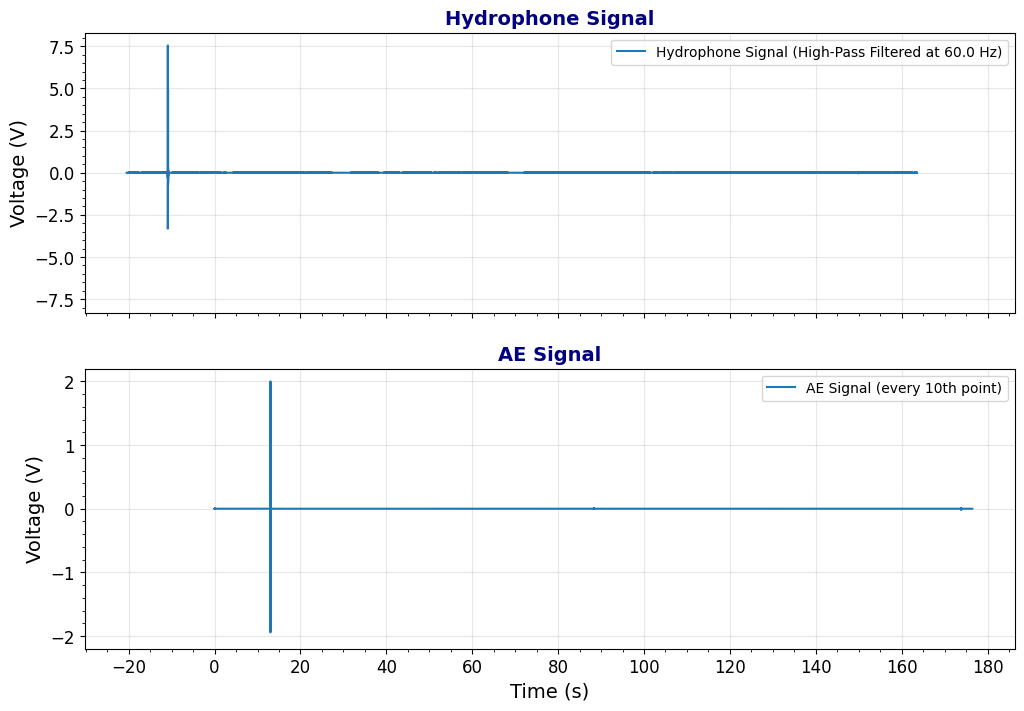

In [8]:
def plot_signals(lvm_data, ae_data, lvm_label: str = "Hydrophone Signal",
                 lvm_marker: float = None, ae_marker: float = None, ae_step: int = 10, legend_loc="upper left",
                 sup_title=None, ae_time_shift=0.0):
    x_ds = ae_data[::ae_step, 0] + ae_time_shift
    y_ds = ae_data[::ae_step, 1]

    if ae_step == 1:
        ae_label = "AE Signal"
    else:
        if ae_step % 100 in (11, 12, 13):  # Special case for 11th, 12th, 13th
            suffix = "th"
        elif ae_step % 10 == 1:
            suffix = "st"
        elif ae_step % 10 == 2:
            suffix = "nd"
        elif ae_step % 10 == 3:
            suffix = "rd"
        else:
            suffix = "th"
            
        ae_label = f"AE Signal (every {ae_step}{suffix} point)"

    y_padding = 1.1

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    ax1.plot(lvm_data[:, 0], lvm_data[:, 1], label=lvm_label)
    if lvm_marker is not None:
        ax1.axvline(x=lvm_marker, color='red', linestyle='--', label=f"Marker at {lvm_marker:.3f}s", alpha=0.7)
    lvm_abs_max = np.max(np.abs(lvm_data[:, 1]))
    ax1.set_ylim(-lvm_abs_max * y_padding, lvm_abs_max * y_padding)
    ax1.set_ylabel('Voltage (V)', fontsize=label_size)
    ax1.set_title('Hydrophone Signal', fontsize=label_size, fontweight='bold', color='navy')
    ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
    ax1.xaxis.set_minor_locator(AutoMinorLocator())
    ax1.yaxis.set_minor_locator(AutoMinorLocator())
    ax1.tick_params(axis='both', which='major', labelsize=tick_size)
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc=legend_loc)

    ax2.plot(x_ds, y_ds, label=ae_label)
    if ae_marker is not None:
        ax2.axvline(x=ae_marker, color='red', linestyle='--', label=f"Marker at {ae_marker:.3f}s", alpha=0.7)
    ae_abs_max = np.max(np.abs(y_ds))
    ax2.set_ylim(-ae_abs_max * y_padding, ae_abs_max * y_padding)
    ax2.set_xlabel("Time (s)", fontsize=label_size)
    ax2.set_ylabel("Voltage (V)", fontsize=label_size)
    ax2.set_title("AE Signal", fontsize=label_size, fontweight='bold', color='navy')
    ax2.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
    ax2.xaxis.set_minor_locator(AutoMinorLocator())
    ax2.yaxis.set_minor_locator(AutoMinorLocator())
    ax2.tick_params(axis='both', which='major', labelsize=tick_size)
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc=legend_loc)

    if sup_title is not None:
        fig.suptitle(sup_title, fontsize=16, fontweight='bold', y=0.95)

    return fig, (ax1, ax2)

plot_signals(high_pass_lvm_data, ae_data, lvm_label=f"Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)", ae_step=10, legend_loc="upper right")
plt.show()

## Synchronize AE to Hydrophone Using the Hammer Hit

Match the early hammer hit using the existing threshold preview. Accept with `done`. This moves AE onto the trigger-referenced hydrophone clock; it does not change the trigger origin or anchor electrical data to the hammer hit.

In [9]:
## Ask User Whether to Synchronize Hydrophone and AE on a Peak
while True:
    sync_data = input("Do you want to synchronize Hydrophone and AE on a peak? (y/n): ").strip().lower()
    if sync_data in ['y', 'n']:
        break

Synced ae_data with adjustment of -23.900171 s. Showing final plot...


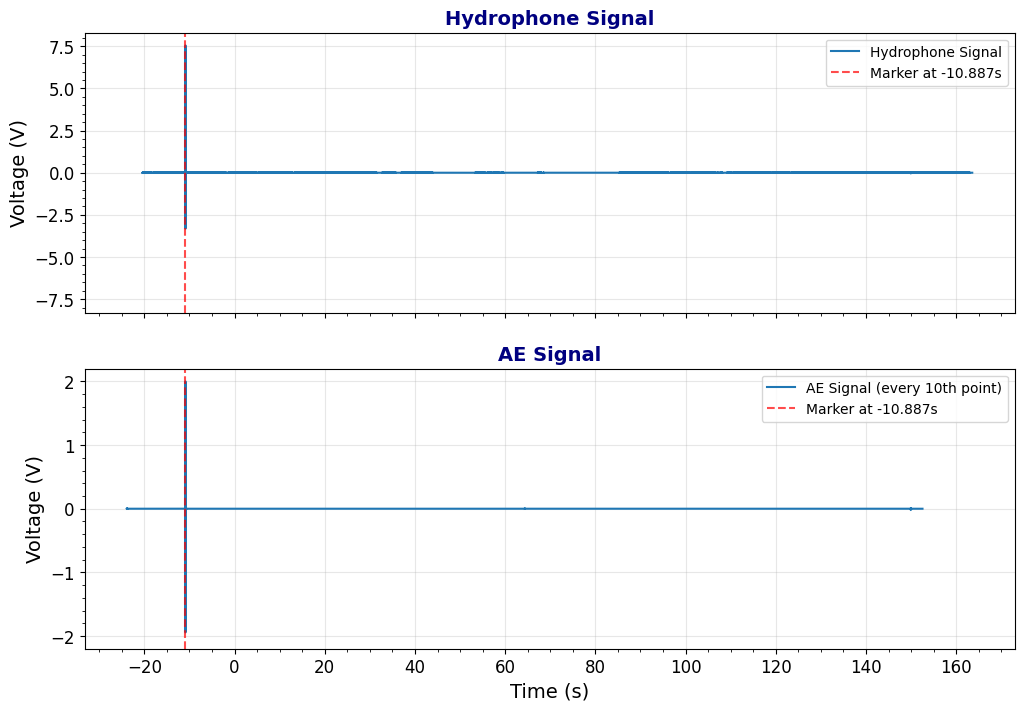

In [10]:
ae_synced_on_peak = False
hydrophone_threshold = 0.5  # V
ae_threshold = 0.5  # V 
if sync_data == 'y':  
    extra_msg = ""  # carries forward any error/warning into the next prompt
    while True:
        status_lines = []
        first_hydrophone_peak_time = None
        first_ae_peak_time = None

        # Carry any message from the previous iteration into this prompt
        if extra_msg:
            status_lines.append(extra_msg)
            extra_msg = ""

        # --- Find hydrophone peak ---
        hydrophone_indices = np.where(np.abs(high_pass_lvm_data[:, 1]) > hydrophone_threshold)[0]
        if len(hydrophone_indices) == 0:
            status_lines.append(f"No hydrophone peaks found above {hydrophone_threshold} V.")
        else:
            first_hydrophone_peak_index = hydrophone_indices[0]
            first_hydrophone_peak_time = high_pass_lvm_data[first_hydrophone_peak_index, 0]
            # status_lines.append(
            #     f"Hydrophone peak above {hydrophone_threshold} V at "
            #     f"t = {first_hydrophone_peak_time:.6f} s (sample {first_hydrophone_peak_index})."
            # )

        # --- Find AE peak ---
        ae_indices = np.where(np.abs(ae_data[:, 1]) > ae_threshold)[0]
        if len(ae_indices) == 0:
            status_lines.append(f"No AE peaks found above {ae_threshold} V.")
        else:
            first_ae_peak_index = ae_indices[0]
            first_ae_peak_time = ae_data[first_ae_peak_index, 0]
            # status_lines.append(
            #     f"AE peak above {ae_threshold} V at "
            #     f"t = {first_ae_peak_time:.6f} s (sample {first_ae_peak_index})."
            # )

        both_found = first_hydrophone_peak_time is not None and first_ae_peak_time is not None

        # --- Plot preview ---
        if both_found:
            time_desync = first_hydrophone_peak_time - first_ae_peak_time
            plt.close('all')
            clear_output(wait=True)
            plot_signals(high_pass_lvm_data, ae_data, ae_time_shift=time_desync,
                         lvm_marker=first_hydrophone_peak_time,
                         ae_marker=first_ae_peak_time + time_desync,  # adjusted to the hydrophone clock
                         ae_step=10,
                         legend_loc="upper right")
            plt.show()
        else:
            plt.close('all')
            clear_output(wait=True)
            plot_signals(high_pass_lvm_data, ae_data, ae_step=10, legend_loc="upper right")
            plt.show()

        # --- Build and show prompt ---
        done_option = " 'done' to apply sync," if both_found else ""
        prompt = (
            "\n".join(status_lines) + "\n"
            f"Enter new thresholds as 'hydro ae' (e.g. '0.3 0.7'),{done_option} or 'quit' to abort: "
        )

        raw = input(prompt).strip()

        if raw.lower() == 'quit':
            print("Sync aborted.")
            break
        elif raw.lower() == 'done':
            if both_found:
                # Apply sync to ae_data and show final plot
                ae_data[:, 0] += time_desync
                ae_synced_on_peak = True
                acoustic_sync_peak_time = float(first_hydrophone_peak_time)
                plt.close('all')
                clear_output(wait=True)
                print(f"Synced ae_data with adjustment of {time_desync:.6f} s. Showing final plot...")
                plot_signals(high_pass_lvm_data, ae_data,
                             lvm_marker=first_hydrophone_peak_time,
                             ae_marker=first_ae_peak_time + time_desync,  # adjusted to the hydrophone clock
                             ae_step=10,
                             legend_loc="upper right")
                plt.show()
                break
            else:
                extra_msg = "'done' is only available when peaks are found for both signals."
        else:
            try:
                hydrophone_threshold, ae_threshold = map(float, raw.split())
            except ValueError:
                extra_msg = f"Invalid input {raw!r}; expected two thresholds, e.g. 0.3 0.7."

## Trim Signals to Same Duration

Hydrophone data time range: -20.435625 s to 163.564297 s
AE data time range: -23.901195 s to 152.531785 s


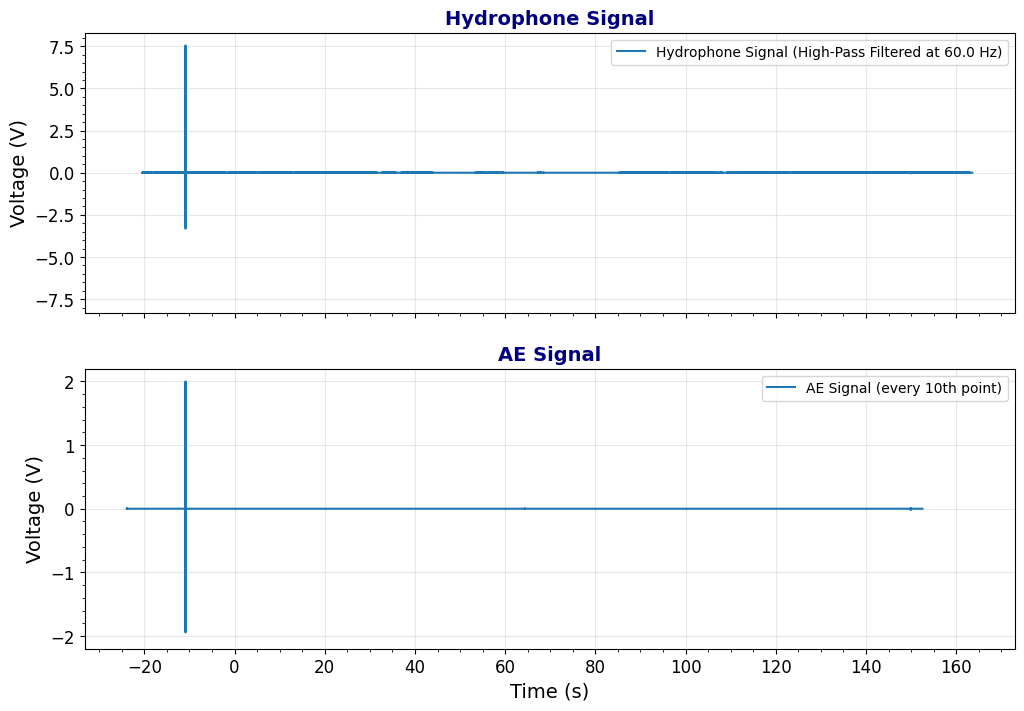

In [11]:
trimmed_lvm_data = lvm_data  # default to untrimmed if not set in the sync block
trimmed_high_pass_lvm_data = high_pass_lvm_data  # default to untrimmed if not set in the sync block
trimmed_ae_data = ae_data  # default to untrimmed if not set in the sync block

# Get the start time and end time of the hydrophone data
start_time_hydrophone = lvm_data[0, 0]
end_time_hydrophone = lvm_data[-1, 0]
print(f"Hydrophone data time range: {start_time_hydrophone:.6f} s to {end_time_hydrophone:.6f} s")

# Get the start time and end time of the AE data
start_time_ae = ae_data[0, 0]
end_time_ae = ae_data[-1, 0]
print(f"AE data time range: {start_time_ae:.6f} s to {end_time_ae:.6f} s")

# Ask whether to limit both signals to their shared time range.
while True:
    trim_response = input("Attempt to trim the hydrophone and AE signals to the same duration? (y/n): ").strip().lower()
    if trim_response in ('y', 'n'):
        break
    print("Invalid response. Please enter 'y' or 'n'.")

trim_to_same_duration = trim_response == 'y'
plot_full_spectrogram_extent = False

if not trim_to_same_duration:
    while True:
        full_extent_response = input(
            "Plot both spectrograms over the full combined time extent, leaving missing regions white? (y/n): "
        ).strip().lower()
        if full_extent_response in ('y', 'n'):
            break
        print("Invalid response. Please enter 'y' or 'n'.")
    plot_full_spectrogram_extent = full_extent_response == 'y'

if trim_to_same_duration and (start_time_ae > end_time_hydrophone or end_time_ae < start_time_hydrophone):
    raise ValueError("Warning: AE data does not overlap with hydrophone data.")

if trim_to_same_duration and not data_trimmed:
    overlap_start = max(start_time_hydrophone, start_time_ae)
    overlap_end = min(end_time_hydrophone, end_time_ae)

    trimmed_lvm_data = lvm_data[
        (lvm_data[:, 0] >= overlap_start) &
        (lvm_data[:, 0] <= overlap_end)
    ]
    trimmed_high_pass_lvm_data = high_pass_lvm_data[
        (high_pass_lvm_data[:, 0] >= overlap_start) &
        (high_pass_lvm_data[:, 0] <= overlap_end)
    ]
    trimmed_ae_data = ae_data[
        (ae_data[:, 0] >= overlap_start) &
        (ae_data[:, 0] <= overlap_end)
    ]

    data_trimmed = True

# Plot trimmed data
plot_signals(trimmed_high_pass_lvm_data, trimmed_ae_data, lvm_label=f"Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)", ae_step=10, legend_loc="upper right")
plt.show()

## Optional: Automatically Attempt to Remove Synchronization Peak

Removed acoustic data before -10.386719 s (accepted hammer hit plus buffer).


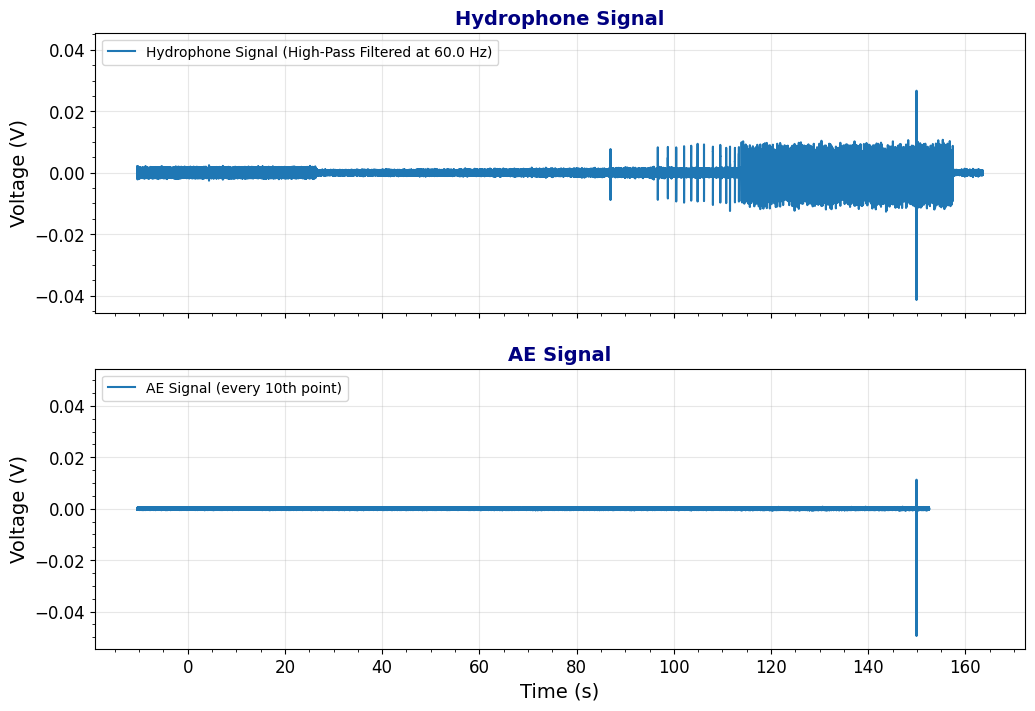

In [12]:
if sync_data == 'y' and ae_synced_on_peak:
    # Ask user if they want to automatically detect and mask out initial synchronization peaks
    while True:
        mask_peaks = input("Do you want to automatically detect and mask out " \
                                "the initial synchronization peak? (y/n): ").strip().lower()
        if mask_peaks in ['y', 'n']:
            break

    if mask_peaks == 'y':
        post_peak_buffer = 0.5  # seconds; retains the original post-hit buffer
        post_peak_cutoff = acoustic_sync_peak_time + post_peak_buffer
        candidates = [array[array[:, 0] >= post_peak_cutoff] for array in
                      (trimmed_lvm_data, trimmed_high_pass_lvm_data, trimmed_ae_data)]
        if any(len(array) < 2 for array in candidates):
            raise ValueError('Removing the hammer hit leaves insufficient acoustic data. Decline removal or review synchronization.')
        trimmed_lvm_data, trimmed_high_pass_lvm_data, trimmed_ae_data = candidates
        print(f'Removed acoustic data before {post_peak_cutoff:.6f} s (accepted hammer hit plus buffer).')

# Plot trimmed data
plot_signals(trimmed_high_pass_lvm_data, trimmed_ae_data, lvm_label=f"Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)", ae_step=10, legend_loc="upper left")
plt.show()

## Load the DC Voltage and PD CSV Exports

Choose the measured DC-voltage CSV and the individual PD-charge CSV. Their `Time [seconds since ... (UTC)]` headers must match. Both elapsed-time columns are retained: CSV **time zero** is initially placed at the accepted hydrophone trigger, even when the first PD pulse occurs much later. A common replacement offset is reviewed in the combined figure below.

The full exports are loaded once into RAM. Voltage is displayed in kV, charge in pC. No AC export or binary `.PD` file is required.

In [13]:
if not trigger_shifted or not trigger_review_accepted:
    raise RuntimeError('Accept the hydrophone trigger and run the time-zeroing cell first.')
if not ae_synced_on_peak:
    raise RuntimeError('Align AE to the hydrophone hammer hit and accept with done before loading electrical data.')


def prompt_dc_export_path(label):
    while True:
        path = Path(input(f'{label} CSV absolute filepath: ').strip().strip(chr(34)).strip(chr(39))).expanduser()
        if path.is_file() and path.suffix.lower() == '.csv':
            return path
        print('Enter the path to an existing CSV file.')


def dc_export_columns(path, value_suffix):
    columns = pd.read_csv(path, sep=';', nrows=0, encoding='utf-8-sig').columns.tolist()
    if (len(columns) != 2 or not columns[0].startswith('Time [seconds since ')
            or not columns[1].endswith(value_suffix)):
        raise ValueError(f'Unexpected columns in {path.name}: {columns}')
    return columns


def load_dc_export(path, columns, value_name):
    frame = pd.read_csv(path, sep=';', encoding='utf-8-sig', dtype=np.float64)
    if frame.columns.tolist() != columns:
        raise ValueError(f'The CSV header changed while loading {path.name}.')
    frame.columns = ['time_s', value_name]
    valid = np.isfinite(frame['time_s']) & np.isfinite(frame[value_name])
    invalid_count = int((~valid).sum())
    if invalid_count:
        print(f'{path.name}: excluding {invalid_count:,} non-finite rows.')
        frame = frame.loc[valid].copy()
    if frame.empty:
        raise ValueError(f'No finite rows in {path.name}.')
    if not frame['time_s'].is_monotonic_increasing:
        frame = frame.sort_values('time_s', kind='stable').reset_index(drop=True)
    print(f'{path.name}: {len(frame):,} rows; elapsed time '
          f'{frame.time_s.iloc[0]:.6f} to {frame.time_s.iloc[-1]:.6f} s.')
    return frame


dc_voltage_path = prompt_dc_export_path('Measured DC voltage')
dc_pd_path = prompt_dc_export_path('DC partial discharge')
voltage_columns = dc_export_columns(dc_voltage_path, 'DC voltage [V]')
pd_columns = dc_export_columns(dc_pd_path, 'PD charge [C]')
if voltage_columns[0] != pd_columns[0]:
    raise ValueError('The voltage and PD CSV time origins differ. Select exports sharing the same time header.')
dc_export_time_header = voltage_columns[0]
dc_voltage_raw = load_dc_export(dc_voltage_path, voltage_columns, 'voltage_V')
dc_pd_raw = load_dc_export(dc_pd_path, pd_columns, 'charge_C')
dc_voltage_time_raw = dc_voltage_raw['time_s'].to_numpy()
dc_voltage_kv_raw = dc_voltage_raw['voltage_V'].to_numpy() * 1e-3
pd_time_s_raw = dc_pd_raw['time_s'].to_numpy()
pd_charge_pc_raw = dc_pd_raw['charge_C'].to_numpy() * 1e12
for array in (dc_voltage_time_raw, dc_voltage_kv_raw, pd_time_s_raw, pd_charge_pc_raw):
    array.setflags(write=False)
manual_DC_time_adjust = 0.0
pd_hexbin_cache = {}
print(f'Shared electrical origin: {dc_export_time_header}')
print('CSV elapsed t = 0 is initially aligned to the hydrophone trigger, not the hammer hit or first pulse.')
print(f'Smallest absolute PD charge in full export: {np.min(np.abs(pd_charge_pc_raw)):.12g} pC.')

PD-acoustic-EMPIRE_147_dcExport_MPD_800_1.1.1_voltage-2026-10-02_15h52m25s.csv: 542 rows; elapsed time 0.174672 to 162.474672 s.
PD-acoustic-EMPIRE_147_dcExport_MPD_800_1.1.1_pd-2026-10-02_15h52m25s.csv: 8,792,963 rows; elapsed time 78.460624 to 162.652007 s.
Shared electrical origin: Time [seconds since 02-Oct-2026 20:52:25.925 (UTC)]
CSV elapsed t = 0 is initially aligned to the hydrophone trigger, not the hammer hit or first pulse.
Smallest absolute PD charge in full export: 10.0034329778 pC.


# Generate and Save Figures

## Optional: Manually Trim Time Range Plotted

In [14]:
# Times (s) over which to mask out the x-axis in later plots
start_time_mask = None
end_time_mask = None

# Save bounds of the current auto-trimmed data
start_trimmed_lvm_data = trimmed_lvm_data[0, 0]
end_trimmed_lvm_data = trimmed_lvm_data[-1, 0]

start_trimmed_high_pass_lvm_data = trimmed_high_pass_lvm_data[0, 0]
end_trimmed_high_pass_lvm_data = trimmed_high_pass_lvm_data[-1, 0]

start_trimmed_ae_data = trimmed_ae_data[0, 0]
end_trimmed_ae_data = trimmed_ae_data[-1, 0]

# Fall back to auto-trimmed bounds when manual bounds are None
lvm_start = start_time_mask if start_time_mask is not None else start_trimmed_lvm_data
lvm_end = end_time_mask if end_time_mask is not None else end_trimmed_lvm_data

high_pass_lvm_start = start_time_mask if start_time_mask is not None else start_trimmed_high_pass_lvm_data
high_pass_lvm_end = end_time_mask if end_time_mask is not None else end_trimmed_high_pass_lvm_data

ae_start = start_time_mask if start_time_mask is not None else start_trimmed_ae_data
ae_end = end_time_mask if end_time_mask is not None else end_trimmed_ae_data

# Re-trim from raw data, but preserve the auto-trimmed range where no manual mask is given
trimmed_lvm_data = lvm_data[
    (lvm_data[:, 0] >= lvm_start) &
    (lvm_data[:, 0] <= lvm_end)
]

trimmed_high_pass_lvm_data = high_pass_lvm_data[
    (high_pass_lvm_data[:, 0] >= high_pass_lvm_start) &
    (high_pass_lvm_data[:, 0] <= high_pass_lvm_end)
]

trimmed_ae_data = ae_data[
    (ae_data[:, 0] >= ae_start) &
    (ae_data[:, 0] <= ae_end)
]


if any(len(array) < 2 for array in (trimmed_lvm_data, trimmed_high_pass_lvm_data, trimmed_ae_data)):
    raise ValueError('The manual plotting interval must leave at least two samples in each acoustic recording.')

def _filename_value(value, decimals=3):
    value = float(value)
    if np.isclose(value, round(value)):
        return str(int(round(value)))
    return f"{value:.{decimals}f}".rstrip("0").rstrip(".").replace(".", "p")


def _freq_token(value_hz):
    value_hz = float(value_hz)
    if abs(value_hz) >= 1000 and np.isclose(value_hz % 1000, 0):
        return f"{int(round(value_hz / 1000))}k"
    return f"{_filename_value(value_hz)}Hz"


def _db_range_token(vmin, vmax):
    return f"{_filename_value(vmin)}to{_filename_value(vmax)}dB"


def time_bounds_suffix(*arrays):
    starts = [arr[0, 0] for arr in arrays if arr is not None and len(arr) > 0]
    ends = [arr[-1, 0] for arr in arrays if arr is not None and len(arr) > 0]
    if not starts or not ends:
        return "tNA-NA"
    return f"t{_filename_value(min(starts))}-{_filename_value(max(ends))}s"


def cutoff_suffix():
    return f"hp{_freq_token(cutoff_freq)}"


def ae_spectrogram_suffix():
    return f"aeSpec_{_freq_token(max_freq_ae_spec)}_{_db_range_token(min_ae_spectrogram_value_ctrl, max_ae_spectrogram_value_ctrl)}"


def hydro_spectrogram_suffix():
    return f"hydSpec_{_freq_token(max_freq_hydro_spec)}_{_db_range_token(min_hydro_spectrogram_value_ctrl, max_hydro_spectrogram_value_ctrl)}"


def figure_suffix(base, *arrays, include_cutoff=False, include_ae_spec=False, include_hydro_spec=False):
    parts = [base, time_bounds_suffix(*arrays)]
    if include_cutoff:
        parts.append(cutoff_suffix())
    if include_ae_spec:
        parts.append(ae_spectrogram_suffix())
    if include_hydro_spec:
        parts.append(hydro_spectrogram_suffix())
    return "_".join(parts)

## Plot Signal Line Graphs

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\ae_only\PD-acoustic-EMPIRE_147_AE_Signal_t-10p387-152p532s.png


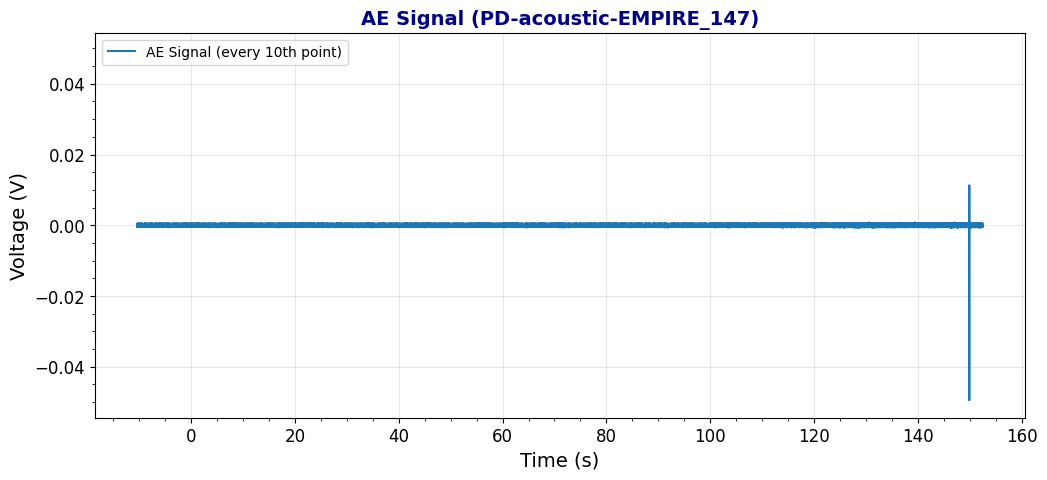

In [15]:
# Plot just AE
ae_step = 10  # plot every nth point to reduce computation (set to 1 to plot all points)
x_ds = trimmed_ae_data[::ae_step, 0]
y_ds = trimmed_ae_data[::ae_step, 1]

if ae_step == 1:
    ae_label = "AE Signal"
else:
    if ae_step % 100 in (11, 12, 13):  # Special case for 11th, 12th, 13th
        suffix = "th"
    elif ae_step % 10 == 1:
        suffix = "st"
    elif ae_step % 10 == 2:
        suffix = "nd"
    elif ae_step % 10 == 3:
        suffix = "rd"
    else:
        suffix = "th"
        
    ae_label = f"AE Signal (every {ae_step}{suffix} point)"

y_padding = 1.1

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(x_ds, y_ds, label=ae_label)
ae_abs_max = np.max(np.abs(y_ds))
ax1.set_ylim(-ae_abs_max * y_padding, ae_abs_max * y_padding)
ax1.set_xlabel("Time (s)", fontsize=label_size)
ax1.set_ylabel("Voltage (V)", fontsize=label_size)
ax1.set_title(f"AE Signal ({lvm_stem})", fontsize=label_size, fontweight='bold', color='navy')
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis='both', which='major', labelsize=tick_size)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

save_figure(fig, figure_suffix("AE_Signal", trimmed_ae_data), category="ae_only", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Unfiltered_Hydrophone_Signal_t-10p387-163p564s.png


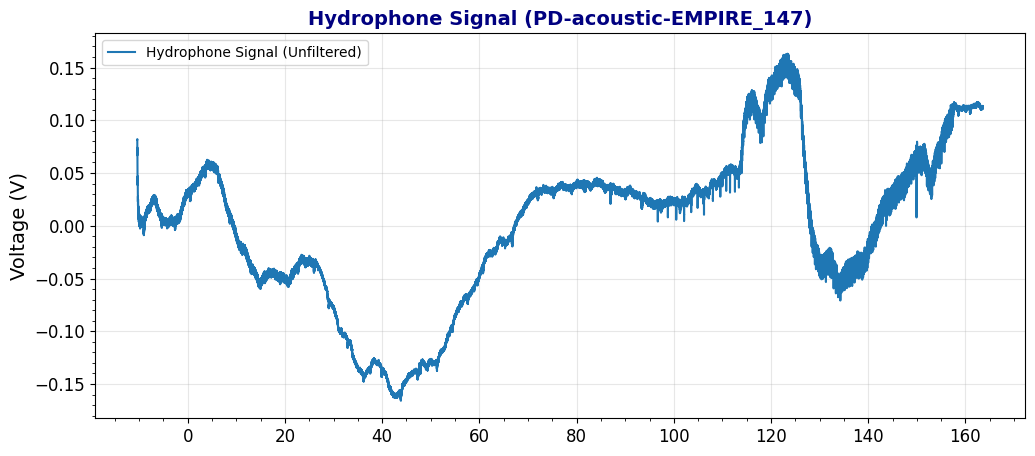

In [16]:
y_padding = 1.1

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(trimmed_lvm_data[:, 0], trimmed_lvm_data[:, 1], label="Hydrophone Signal (Unfiltered)")
lvm_abs_max = np.max(np.abs(trimmed_lvm_data[:, 1]))
ax1.set_ylim(-lvm_abs_max * y_padding, lvm_abs_max * y_padding)
ax1.set_ylabel('Voltage (V)', fontsize=label_size)
ax1.set_title(f"Hydrophone Signal ({lvm_stem})", fontsize=label_size, fontweight='bold', color='navy')
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis='both', which='major', labelsize=tick_size)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

save_figure(fig, figure_suffix("Unfiltered_Hydrophone_Signal", trimmed_lvm_data), category="hydrophone_only", dpi=figure_dpi)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Filtered_Hydrophone_Signal_t-10p387-163p564s_hp60Hz.png


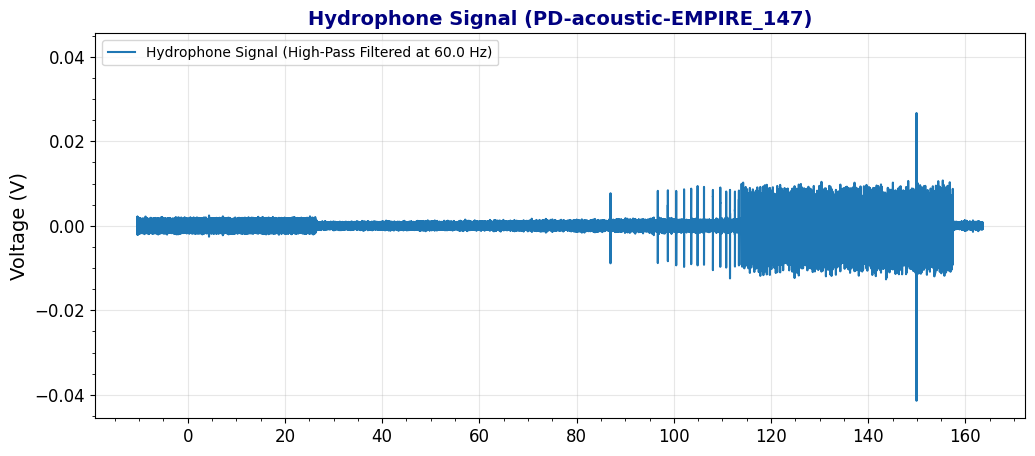

In [17]:
y_padding = 1.1

fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(trimmed_high_pass_lvm_data[:, 0], trimmed_high_pass_lvm_data[:, 1], label=f"Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)")
lvm_abs_max = np.max(np.abs(trimmed_high_pass_lvm_data[:, 1]))
ax1.set_ylim(-lvm_abs_max * y_padding, lvm_abs_max * y_padding)
ax1.set_ylabel('Voltage (V)', fontsize=label_size)
ax1.set_title(f"Hydrophone Signal ({lvm_stem})", fontsize=label_size, fontweight='bold', color='navy')
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis='both', which='major', labelsize=tick_size)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

save_figure(fig, figure_suffix("Filtered_Hydrophone_Signal", trimmed_high_pass_lvm_data, include_cutoff=True), category="hydrophone_only", dpi=figure_dpi)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_AE_and_Unfiltered_Hydrophone_Signal_t-10p387-163p564s.png


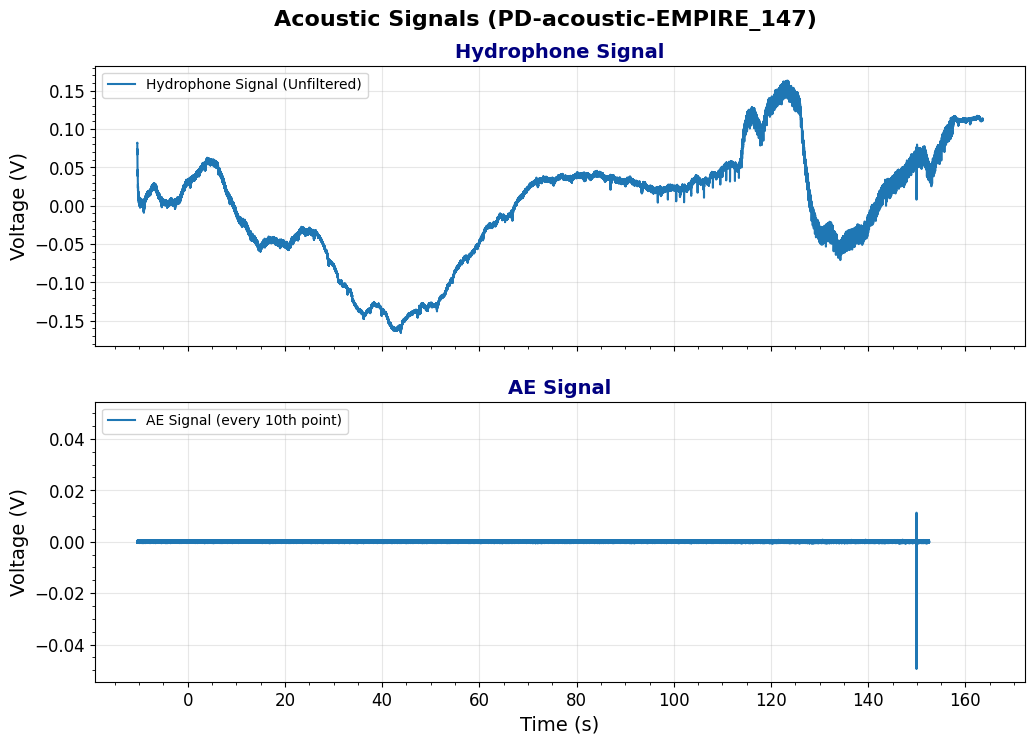

In [18]:
# Plot AE and unfiltered hydrophone data
fig, _ = plot_signals(trimmed_lvm_data, trimmed_ae_data, lvm_label="Hydrophone Signal (Unfiltered)", ae_step=10, sup_title=f"Acoustic Signals ({lvm_stem})", legend_loc="upper left")
save_figure(fig, figure_suffix("AE_and_Unfiltered_Hydrophone_Signal", trimmed_lvm_data, trimmed_ae_data), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_AE_and_Filtered_Hydrophone_Signal_t-10p387-163p564s_hp60Hz.png


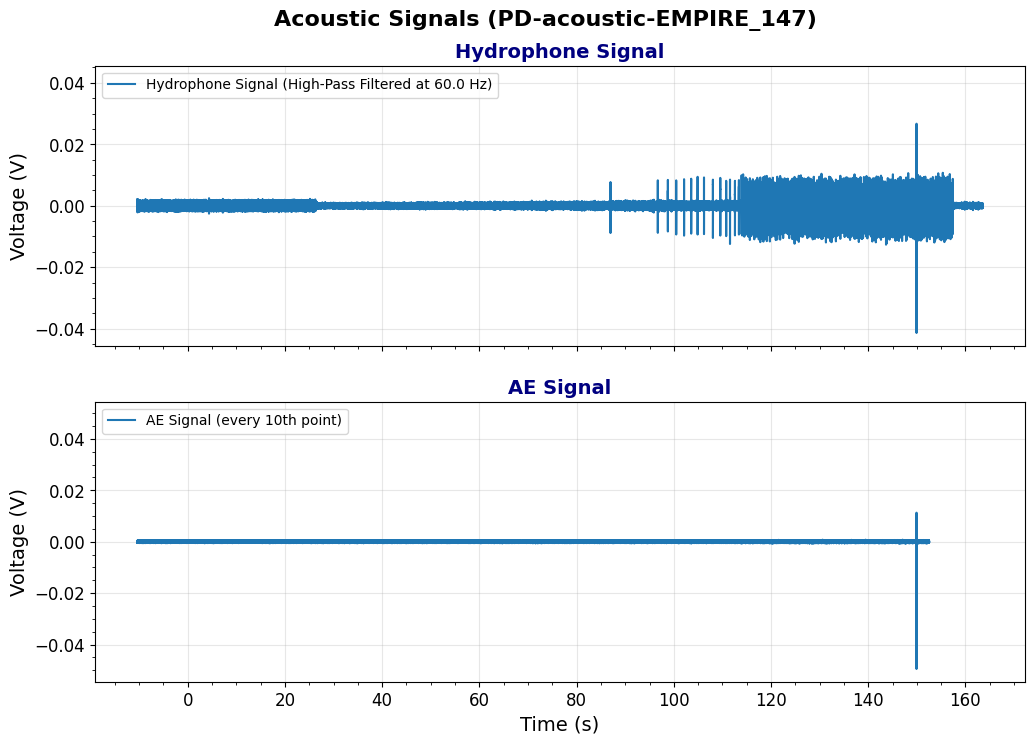

In [19]:
# Plot AE and filtered hydrophone data
fig, _ = plot_signals(trimmed_high_pass_lvm_data, trimmed_ae_data, lvm_label=f"Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)", ae_step=10, sup_title=f"Acoustic Signals ({lvm_stem})")
save_figure(fig, figure_suffix("AE_and_Filtered_Hydrophone_Signal", trimmed_high_pass_lvm_data, trimmed_ae_data, include_cutoff=True), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()

## Calculate Hydrophone RMS Amplitude

In [20]:
# RMS Amplitude over windowed time segments (vectorised)
hydrophone_window_duration = 0.01  # Window size in seconds

hydrophone_time = trimmed_lvm_data[:, 0]
hydrophone_signal = trimmed_lvm_data[:, 1]
hydrophone_time_hp = trimmed_high_pass_lvm_data[:, 0]
hydrophone_signal_hp = trimmed_high_pass_lvm_data[:, 1]

# Infer sample rate from data and derive samples per window
dt = np.mean(np.diff(hydrophone_time[:1000]))          # Use first 1000 diffs for speed
sample_rate = 1.0 / dt
samples_per_window = max(1, int(round(hydrophone_window_duration * sample_rate)))

# Truncate signal so it divides evenly into windows
n_windows = len(hydrophone_signal) // samples_per_window
signal_trimmed = hydrophone_signal[:n_windows * samples_per_window]
time_trimmed   = hydrophone_time[:n_windows * samples_per_window]
signal_hp_trimmed = hydrophone_signal_hp[:n_windows * samples_per_window]
time_hp_trimmed   = hydrophone_time_hp[:n_windows * samples_per_window]

# Reshape to (n_windows, samples_per_window), then calculate RMS along axis=1.
windows    = signal_trimmed.reshape(n_windows, samples_per_window)
hydrophone_rms_values = np.sqrt(np.mean(windows ** 2, axis=1))
hp_windows = signal_hp_trimmed.reshape(n_windows, samples_per_window)
hydrophone_rms_values_hp = np.sqrt(np.mean(hp_windows ** 2, axis=1))

# Use the midpoint of each window as its time label
hydrophone_rms_times  = time_trimmed.reshape(n_windows, samples_per_window)[:, samples_per_window // 2]
hydrophone_rms_times_hp  = time_hp_trimmed.reshape(n_windows, samples_per_window)[:, samples_per_window // 2]

## Plot Hydrophone RMS Amplitude

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Unfiltered_Hydrophone_RMS_Amplitude_t-10p387-163p564s.png


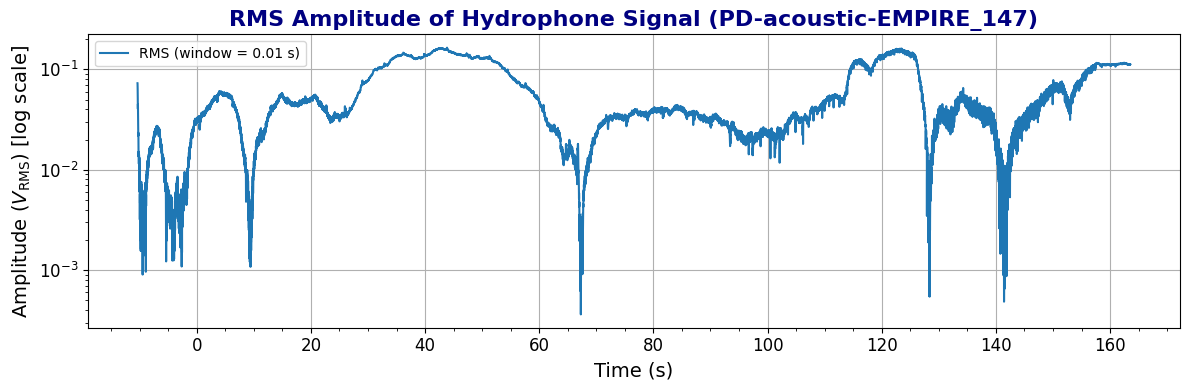

In [21]:
plot_log_scale = True  # Set to True to use logarithmic scale for RMS plot

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hydrophone_rms_times, hydrophone_rms_values, label=f"RMS (window = {hydrophone_window_duration} s)")
ax.set_xlabel("Time (s)", fontsize=label_size)
if plot_log_scale:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax.set_yscale("log")
else:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax.set_title(f"RMS Amplitude of Hydrophone Signal ({lvm_stem})", fontsize=16, fontweight='bold', color='navy')
ax.grid(True)
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(MaxNLocator(nbins=10, steps=[1, 2, 2.5, 5, 10]))
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(axis='both', which='major', labelsize=tick_size)
fig.tight_layout()

save_figure(fig, figure_suffix("Unfiltered_Hydrophone_RMS_Amplitude", trimmed_lvm_data), category="hydrophone_only", dpi=figure_dpi)
plt.show()

## Plot Filtered Hydrophone RMS Amplitude

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Filtered_Hydrophone_RMS_Amplitude_t-10p387-163p564s_hp60Hz.png


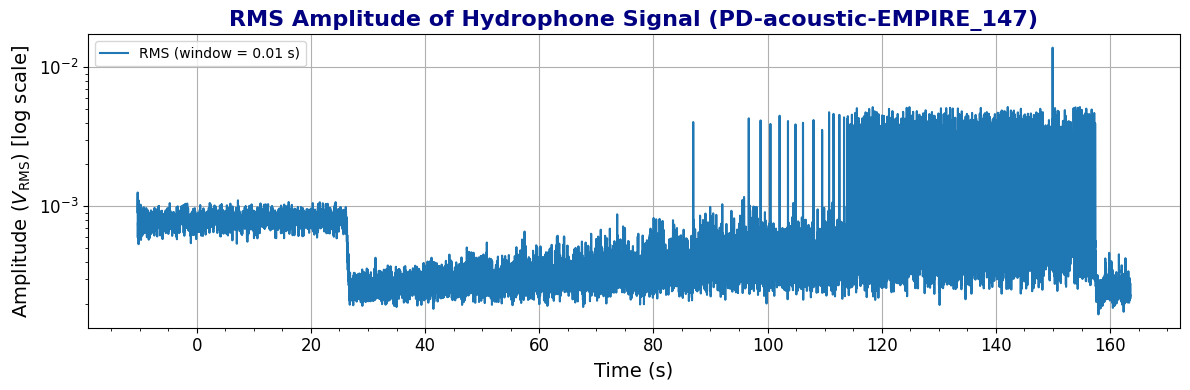

In [22]:
plot_log_scale = True  # Set to True to use logarithmic scale for RMS plot

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hydrophone_rms_times_hp, hydrophone_rms_values_hp, label=f"RMS (window = {hydrophone_window_duration} s)")
ax.set_xlabel("Time (s)", fontsize=label_size)
if plot_log_scale:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax.set_yscale("log")
else:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax.set_title(f"RMS Amplitude of Hydrophone Signal ({lvm_stem})", fontsize=16, fontweight='bold', color='navy')
ax.grid(True)
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(axis='both', which='major', labelsize=tick_size)
fig.tight_layout()

save_figure(fig, figure_suffix("Filtered_Hydrophone_RMS_Amplitude", trimmed_high_pass_lvm_data, include_cutoff=True), category="hydrophone_only", dpi=figure_dpi)
plt.show()

## Calculate AE RMS Amplitude

In [23]:
# RMS Amplitude over windowed time segments (vectorised)
ae_window_duration = 0.01  # Window size in seconds

ae_time = trimmed_ae_data[:, 0]
ae_signal = trimmed_ae_data[:, 1]

# Infer sample rate from data and derive samples per window
dt = np.mean(np.diff(ae_time[:1000]))          # Use first 1000 diffs for speed
sample_rate = 1.0 / dt
samples_per_window = max(1, int(round(ae_window_duration * sample_rate)))

# Truncate signal so it divides evenly into windows
n_windows = len(ae_signal) // samples_per_window
signal_trimmed = ae_signal[:n_windows * samples_per_window]
time_trimmed   = ae_time[:n_windows * samples_per_window]

# Reshape to (n_windows, samples_per_window), then calculate RMS along axis=1.
windows    = signal_trimmed.reshape(n_windows, samples_per_window)
ae_rms_values = np.sqrt(np.mean(windows ** 2, axis=1))

# Use the midpoint of each window as its time label
ae_rms_times  = time_trimmed.reshape(n_windows, samples_per_window)[:, samples_per_window // 2]

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\ae_only\PD-acoustic-EMPIRE_147_AE_RMS_Amplitude_t-10p387-152p532s.png


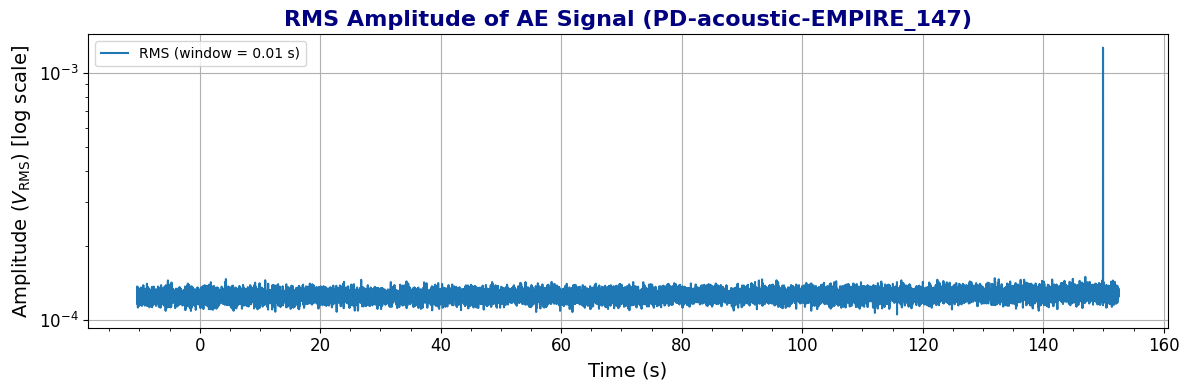

In [24]:
plot_log_scale = True  # Set to True to use logarithmic scale for RMS plot

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ae_rms_times, ae_rms_values, label=f"RMS (window = {ae_window_duration} s)")
ax.set_xlabel("Time (s)", fontsize=label_size)
if plot_log_scale:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax.set_yscale("log")
else:
    ax.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax.set_title(f"RMS Amplitude of AE Signal ({lvm_stem})", fontsize=16, fontweight='bold', color='navy')
ax.grid(True)
ax.legend(loc="upper left")
ax.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax.xaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(axis='both', which='major', labelsize=tick_size)
fig.tight_layout()

save_figure(fig, figure_suffix("AE_RMS_Amplitude", trimmed_ae_data), category="ae_only", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_Hydrophone_Unfiltered_AE_RMS_Amplitude_t-10p387-163p564s.png


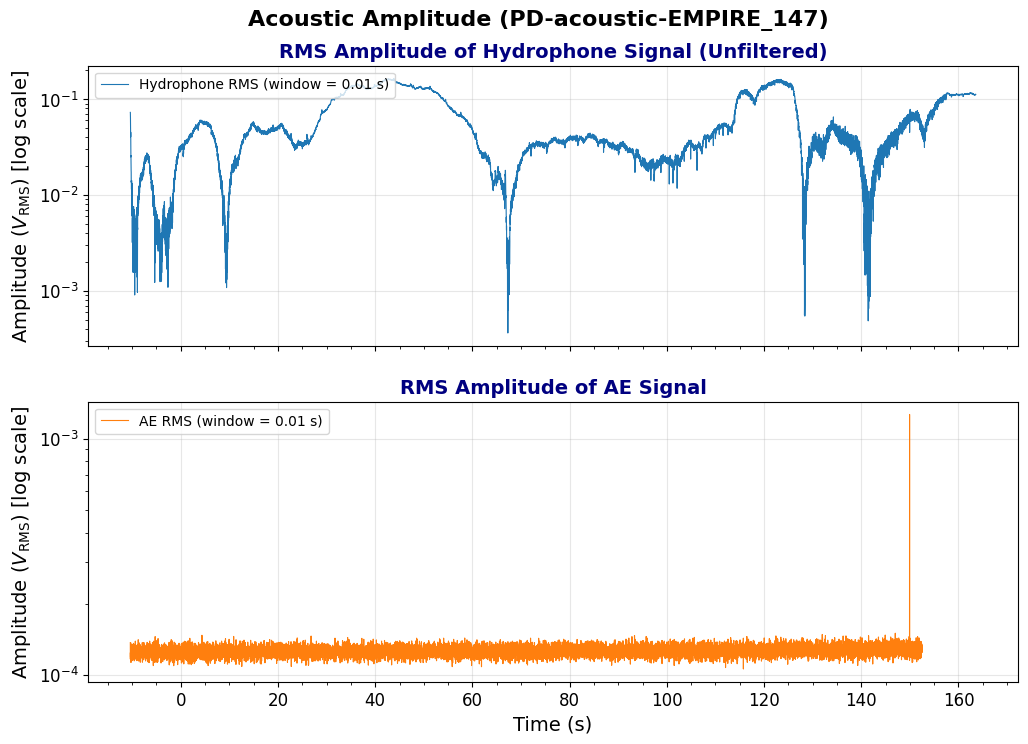

In [25]:
plot_log_scale = True  # Set to True to use logarithmic scale for RMS plots

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Hydrophone Amplitude (Unfiltered) ---
ax1.plot(
    hydrophone_rms_times,
    hydrophone_rms_values,
    color="tab:blue",
    linewidth=0.8,
    label=f"Hydrophone RMS (window = {hydrophone_window_duration} s)"
)
ax1.set_title("RMS Amplitude of Hydrophone Signal (Unfiltered)", fontsize=label_size, fontweight="bold", color='navy')
if plot_log_scale:
    ax1.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax1.set_yscale("log")
else:
    ax1.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis="both", which="major", labelsize=tick_size)

# --- AE Amplitude ---
ax2.plot(
    ae_rms_times,
    ae_rms_values,
    color="tab:orange",
    linewidth=0.8,
    label=f"AE RMS (window = {ae_window_duration} s)"
)
ax2.set_xlabel("Time (s)", fontsize=label_size)
ax2.set_title("RMS Amplitude of AE Signal", fontsize=label_size, fontweight="bold", color='navy')
if plot_log_scale:
    ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax2.set_yscale("log")
else:
    ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left")
ax2.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax2.xaxis.set_minor_locator(AutoMinorLocator())
ax2.tick_params(axis="both", which="major", labelsize=tick_size)

fig.suptitle(
    f"Acoustic Amplitude ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.95
)

# fig.tight_layout()

save_figure(fig, figure_suffix("Hydrophone_Unfiltered_AE_RMS_Amplitude", trimmed_lvm_data, trimmed_ae_data), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()


Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_Hydrophone_High_Pass_Filtered_AE_RMS_Amplitude_t-10p387-163p564s_hp60Hz.png


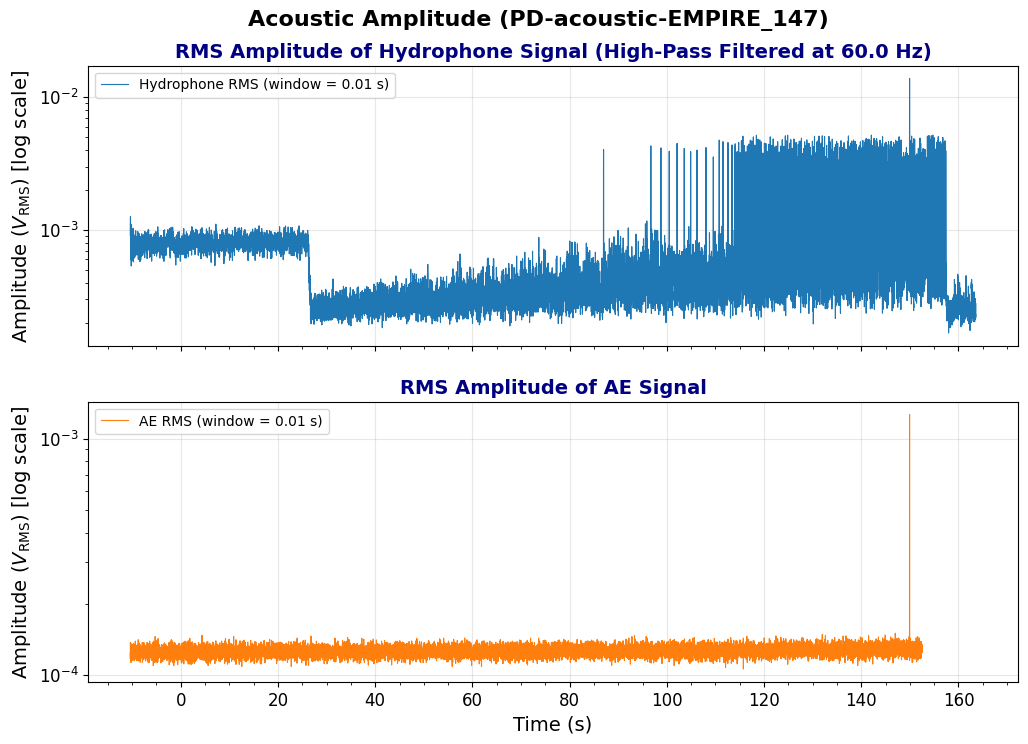

In [26]:
plot_log_scale = True  # Set to True to use logarithmic scale for RMS plots

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# --- Hydrophone Amplitude (High-Pass Filtered) ---
ax1.plot(
    hydrophone_rms_times_hp,
    hydrophone_rms_values_hp,
    color="tab:blue",
    linewidth=0.8,
    label=f"Hydrophone RMS (window = {hydrophone_window_duration} s)"
)
ax1.set_title(f"RMS Amplitude of Hydrophone Signal (High-Pass Filtered at {cutoff_freq} Hz)", fontsize=label_size, fontweight="bold", color='navy')
if plot_log_scale:
    ax1.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax1.set_yscale("log")
else:
    ax1.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis="both", which="major", labelsize=tick_size)

# --- AE Amplitude ---
ax2.plot(
    ae_rms_times,
    ae_rms_values,
    color="tab:orange",
    linewidth=0.8,
    label=f"AE RMS (window = {ae_window_duration} s)"
)
ax2.set_xlabel("Time (s)", fontsize=label_size)
ax2.set_title("RMS Amplitude of AE Signal", fontsize=label_size, fontweight="bold", color='navy')
if plot_log_scale:
    ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$) [log scale]", fontsize=label_size)
    ax2.set_yscale("log")
else:
    ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left")
ax2.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax2.xaxis.set_minor_locator(AutoMinorLocator())
ax2.tick_params(axis="both", which="major", labelsize=tick_size)

fig.suptitle(
    f"Acoustic Amplitude ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.95
)

# fig.tight_layout()

hp_ae_amplitude_comparative_path = save_figure(fig, figure_suffix("Hydrophone_High_Pass_Filtered_AE_RMS_Amplitude", trimmed_high_pass_lvm_data, trimmed_ae_data, include_cutoff=True), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()

## Define Spectrogram Utilities

In [27]:
# Define helper functions for batched Welch and spectrogram calculations that can handle very 
# long AE streams without running out of memory.

def _as_float64_1d(values):
    values = np.asarray(values, dtype=np.float64)
    if values.ndim != 1:
        values = np.ravel(values)
    return values


def _double_onesided_power(power, nperseg):
    if nperseg % 2 == 0:
        if power.shape[-1] > 2:
            power[..., 1:-1] *= 2.0
    elif power.shape[-1] > 1:
        power[..., 1:] *= 2.0
    return power


def welch_batched(signal, fs, nperseg=4096, noverlap=None, max_segments_per_batch=1024):
    """Welch PSD with bounded memory for very long 1-D AE streams."""
    signal = _as_float64_1d(signal)
    n_samples = signal.size
    if n_samples == 0:
        raise ValueError('AE signal is empty.')

    nperseg = int(max(8, min(nperseg, n_samples)))
    if noverlap is None:
        noverlap = nperseg // 2
    noverlap = int(max(0, min(noverlap, nperseg - 1)))
    hop = nperseg - noverlap
    n_segments = 1 + max(0, (n_samples - nperseg) // hop)

    win = get_window('hann', nperseg).astype(np.float64, copy=False)
    scale = 1.0 / (float(fs) * np.sum(win ** 2))
    freqs = np.fft.rfftfreq(nperseg, d=1.0 / float(fs))
    psd_sum = np.zeros(freqs.shape, dtype=np.float64)

    sample_stride = signal.strides[0]
    segments = as_strided(
        signal,
        shape=(n_segments, nperseg),
        strides=(hop * sample_stride, sample_stride),
        writeable=False,
    )

    for start in range(0, n_segments, max_segments_per_batch):
        stop = min(start + max_segments_per_batch, n_segments)
        batch = segments[start:stop]
        batch = batch - np.mean(batch, axis=1, keepdims=True)
        ffts = np.fft.rfft(batch * win[np.newaxis, :], axis=1)
        power = (np.abs(ffts) ** 2) * scale
        power = _double_onesided_power(power, nperseg)
        psd_sum += np.sum(power, axis=0)

    return freqs, psd_sum / n_segments, n_segments, hop, nperseg


def spectrogram_strided_batched(signal, fs, nperseg=4096, n_time_bins=2400, max_segments_per_batch=512):
    """Display-oriented spectrogram capped to roughly n_time_bins columns."""
    signal = _as_float64_1d(signal)
    n_samples = signal.size
    if n_samples == 0:
        raise ValueError('AE signal is empty.')

    n_time_bins = int(max(1, n_time_bins))
    step = max(1, n_samples // n_time_bins)
    nperseg = int(max(8, min(nperseg, n_samples)))
    n_segments = 1 + max(0, (n_samples - nperseg) // step)

    win = get_window('hann', nperseg).astype(np.float64, copy=False)
    scale = 1.0 / (float(fs) * np.sum(win ** 2))
    freqs = np.fft.rfftfreq(nperseg, d=1.0 / float(fs))
    sxx = np.empty((freqs.size, n_segments), dtype=np.float32)

    sample_stride = signal.strides[0]
    segments = as_strided(
        signal,
        shape=(n_segments, nperseg),
        strides=(step * sample_stride, sample_stride),
        writeable=False,
    )

    for start in range(0, n_segments, max_segments_per_batch):
        stop = min(start + max_segments_per_batch, n_segments)
        batch = segments[start:stop]
        batch = batch - np.mean(batch, axis=1, keepdims=True)
        ffts = np.fft.rfft(batch * win[np.newaxis, :], axis=1)
        power = (np.abs(ffts) ** 2) * scale
        power = _double_onesided_power(power, nperseg)
        sxx[:, start:stop] = power.T.astype(np.float32, copy=False)

    times = (np.arange(n_segments, dtype=np.float64) * step + nperseg / 2) / float(fs)
    return freqs, times, sxx, step, nperseg

## Calculate AE Spectrogram

In [28]:
# Compute a display-oriented spectrogram with bounded time bins.

max_freq_ae_spec = 200e3  # Frequency (Hz) over which to mask out the y-axis

nperseg_ae_spec = 4096*64  # Number of samples per segment for AE spectrogram (controls frequency-axis resolution)
ae_spectrogram_time_bins = 1080  # Increase for more time-axis resolution; 
# memory scales with frequency_bins * spectrogram_time_bins.

ae_frequencies, ae_rel_times, ae_Sxx, ae_spectrogram_step, ae_spectrogram_nperseg = spectrogram_strided_batched(
    trimmed_ae_data[:, 1],
    ae_sample_rate,
    nperseg=nperseg_ae_spec,
    n_time_bins=ae_spectrogram_time_bins,
    max_segments_per_batch=64,
)
ae_Sxx_log = 10 * np.log10(np.maximum(ae_Sxx, np.finfo(np.float32).tiny))

print(
    f"Strided AE spectrogram shape: {ae_Sxx_log.shape}, "
    f"step={ae_spectrogram_step:,} samples, nperseg={ae_spectrogram_nperseg:,}"
)

ae_sync_times = ae_rel_times + trimmed_ae_data[0, 0]
print(f"AE relative time range: {ae_rel_times[0]:.6f} s to {ae_rel_times[-1]:.6f} s")
print(f"AE absolute time range: {ae_sync_times[0]:.6f} s to {ae_sync_times[-1]:.6f} s")

freq_mask = ae_frequencies <= max_freq_ae_spec
ae_masked_frequencies = ae_frequencies[freq_mask]
ae_masked_Sxx_log = ae_Sxx_log[freq_mask, :]
print(f"Masked AE Sxx_log shape: {ae_masked_Sxx_log.shape}")

Strided AE spectrogram shape: (131073, 1079), step=150,850 samples, nperseg=262,144
AE relative time range: 0.131072 s to 162.747372 s
AE absolute time range: -10.255647 s to 152.360653 s
Masked AE Sxx_log shape: (52429, 1079)


## Calculate Hydrophone Spectrogram

In [29]:
# --- Calculate spectrogram for the unfiltered hydrophone signal ---
max_freq_hydro_spec = 12e3  # Frequency (Hz) over which to mask out the y-axis
nperseg_hydro_spec = 1024  # Number of samples per segment for hydrophone spectrogram
noverlap_hydro_spec = nperseg_hydro_spec // 2  # Number of overlapping samples for hydrophone spectrogram

hydrophone_frequencies, hydrophone_rel_times, hydrophone_Sxx = spectrogram(
    trimmed_lvm_data[:, 1],
    hydrophone_sample_rate,
    scaling='spectrum',
    nperseg=nperseg_hydro_spec,
    noverlap=noverlap_hydro_spec,
)
hydrophone_Sxx_log = 10 * np.log10(np.maximum(hydrophone_Sxx, np.finfo(np.float32).tiny))

hydrophone_sync_times = hydrophone_rel_times + trimmed_lvm_data[0, 0]
print(f"Hydrophone relative time range: {hydrophone_rel_times[0]:.6f} s to {hydrophone_rel_times[-1]:.6f} s")
print(f"Hydrophone absolute time range: {hydrophone_sync_times[0]:.6f} s to {hydrophone_sync_times[-1]:.6f} s")

freq_mask = hydrophone_frequencies <= max_freq_hydro_spec
hydrophone_masked_frequencies = hydrophone_frequencies[freq_mask]
hydrophone_masked_Sxx_log = hydrophone_Sxx_log[freq_mask, :]
print(f"Masked Hydrophone Sxx_log shape: {hydrophone_masked_Sxx_log.shape}")



# --- Calculate spectrogram for the high-pass filtered hydrophone signal ---
hydrophone_hp_frequencies, hydrophone_hp_rel_times, hydrophone_hp_Sxx = spectrogram(
    trimmed_high_pass_lvm_data[:, 1],
    hydrophone_sample_rate,
    scaling='spectrum',
    nperseg=nperseg_hydro_spec,
    noverlap=noverlap_hydro_spec,
)
hydrophone_hp_Sxx_log = 10 * np.log10(np.maximum(hydrophone_hp_Sxx, np.finfo(np.float32).tiny))

hydrophone_hp_sync_times = hydrophone_hp_rel_times + trimmed_high_pass_lvm_data[0, 0]
print(f"Hydrophone HP relative time range: {hydrophone_hp_rel_times[0]:.6f} s to {hydrophone_hp_rel_times[-1]:.6f} s")
print(f"Hydrophone HP absolute time range: {hydrophone_hp_sync_times[0]:.6f} s to {hydrophone_hp_sync_times[-1]:.6f} s")

freq_mask = hydrophone_hp_frequencies <= max_freq_hydro_spec
hydrophone_hp_masked_frequencies = hydrophone_hp_frequencies[freq_mask]
hydrophone_hp_masked_Sxx_log = hydrophone_hp_Sxx_log[freq_mask, :]
print(f"Masked Hydrophone HP Sxx_log shape: {hydrophone_hp_masked_Sxx_log.shape}")

Hydrophone relative time range: 0.040000 s to 173.880000 s
Hydrophone absolute time range: -10.346719 s to 163.493281 s
Masked Hydrophone Sxx_log shape: (513, 4347)
Hydrophone HP relative time range: 0.040000 s to 173.880000 s
Hydrophone HP absolute time range: -10.346719 s to 163.493281 s
Masked Hydrophone HP Sxx_log shape: (513, 4347)


## Plot Spectrograms

### Set AE Spectrogram Parameters

In [30]:
max_ae_spectrogram_value_ctrl = -110
min_ae_spectrogram_value_ctrl = -145
ae_cmap = 'viridis'

### Set Hydrophone Spectrogram Parameters

In [31]:
max_hydro_spectrogram_value_ctrl = -60
min_hydro_spectrogram_value_ctrl = -100
hydro_cmap = 'viridis'

## Hydrophone, AE, DC Voltage, and PD Synchronization Preview

The 2x2 figure uses **seconds from the accepted hydrophone trigger**. The hammer hit has already aligned AE to the hydrophone. Enter a replacement electrical offset in seconds: **positive moves both CSVs later**. Every entry redraws the preview; `done` accepts and saves it. Both CSVs always receive the same offset.

Electrical data ends at the later retained acoustic end when forced overlap is declined, or at the shared end when overlap is accepted. Optional peak removal and manual plotting bounds also govern the displayed interval. Raw CSV timestamps remain intact so an offset change can restore previously clipped samples.

All PD events in the displayed interval are binned. Counts and geometry are reused when an offset change retains the same event selection. `PD_CHARGE_SCALE = 'signed_log'` uses the EasyAE signed, shifted log10 mapping; exact zeros are excluded and the center labels the reference magnitude rather than zero. Set it to `'linear'` for the original charge axis. The minimum absolute charge is printed for each displayed interval.

Electrical display ends at 163.564297 s on the acoustic clock.
Smallest absolute PD charge in displayed interval: 10.0034329778 pC.


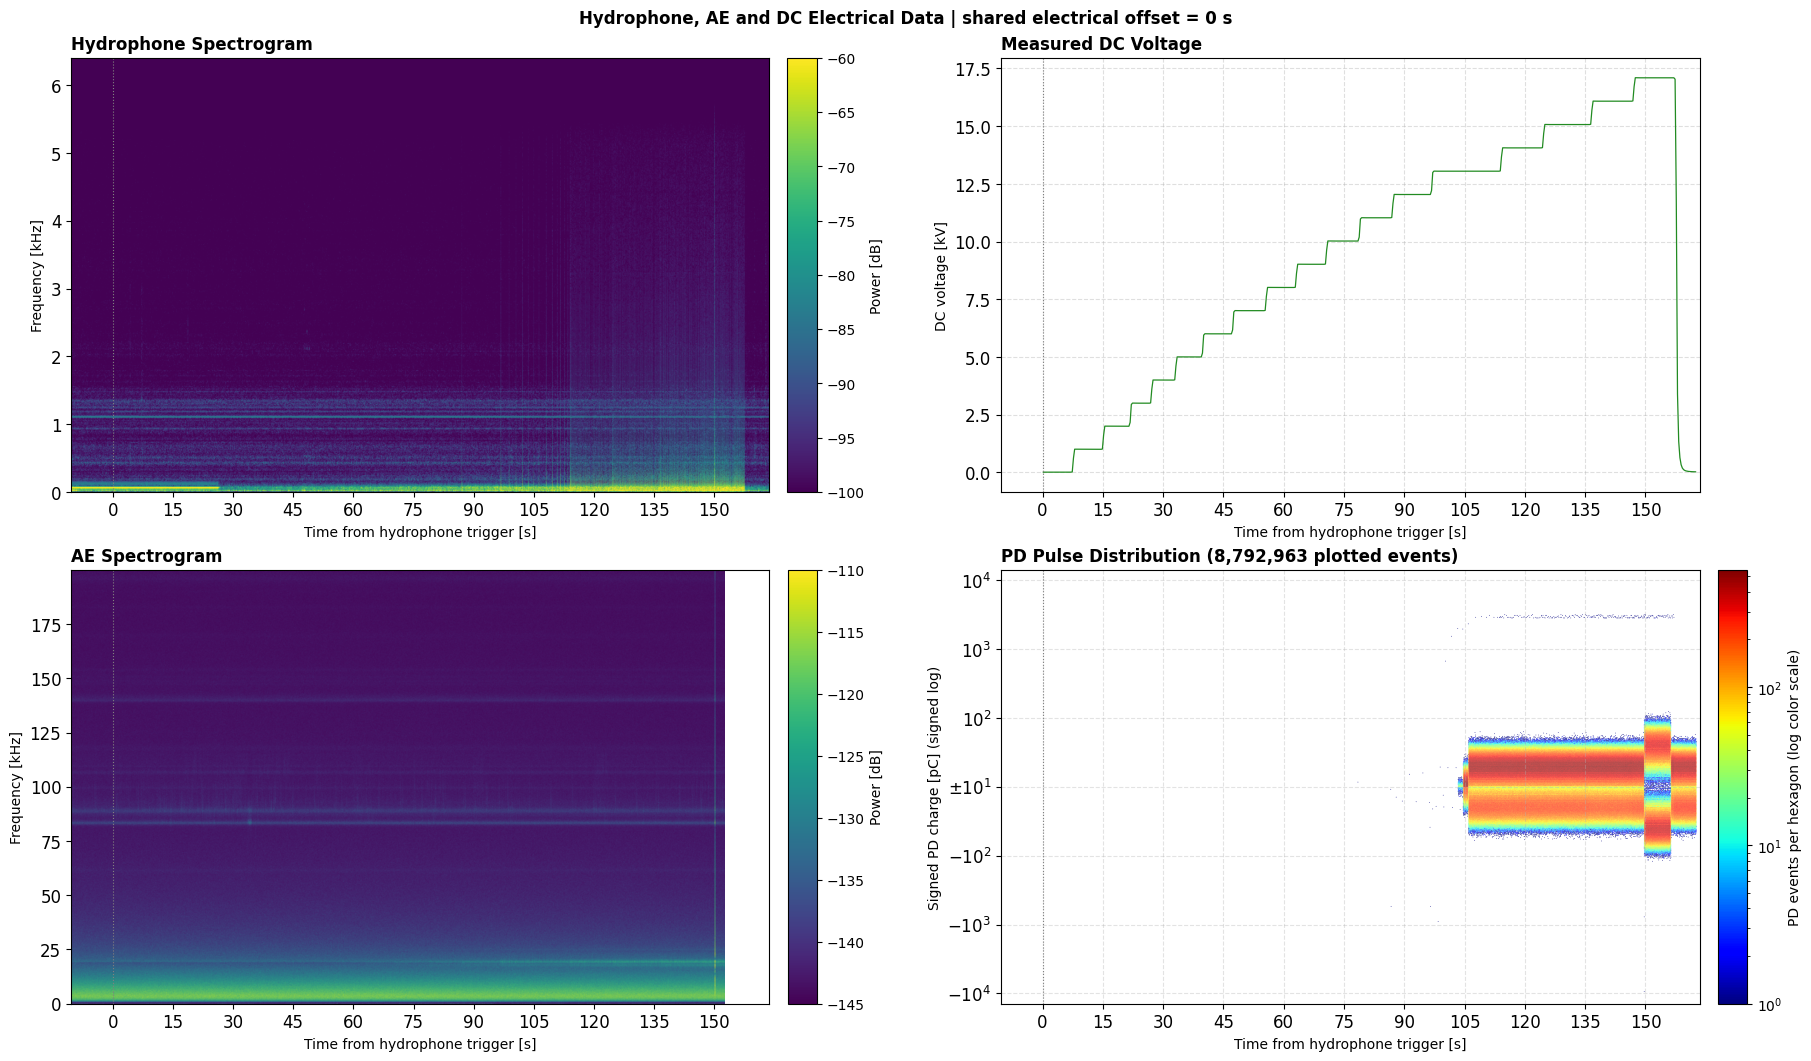

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\combined\PD-acoustic-EMPIRE_147_Hydrophone_AE_MPD_DC_PD_Combined_t-10p387-163p564s_aeSpec_200k_-145to-110dB_hydSpec_12k_-100to-60dB_shift0s.png
Accepted shared DC CSV offset: 0 s.
Retained 542 voltage rows and 8,792,963 PD pulses within the acoustic interval.


In [32]:
from matplotlib.colors import LogNorm
from matplotlib.collections import PolyCollection
from matplotlib.transforms import AffineDeltaTransform

PD_CHARGE_SCALE = 'signed_log'  # 'signed_log' or 'linear'
PD_HEXBIN_GRIDSIZE = 500
PD_CMAP = 'jet'
# Retain the accepted value when rerunning this cell; loading new CSVs resets it.
manual_DC_time_adjust = globals().get('manual_DC_time_adjust', 0.0)


def electrical_plot_bounds():
    starts = [float(trimmed_lvm_data[0, 0]), float(trimmed_ae_data[0, 0])]
    ends = [float(trimmed_lvm_data[-1, 0]), float(trimmed_ae_data[-1, 0])]
    start = float(start_time_mask) if start_time_mask is not None else min(starts)
    end = min(ends) if trim_to_same_duration else max(ends)
    if end_time_mask is not None:
        end = min(end, float(end_time_mask))
    if not np.isfinite([start, end]).all() or start >= end:
        raise ValueError('The selected acoustic plotting interval must have finite start < end.')
    return start, end


def electrical_event_slice(raw_times, offset, bounds):
    # Select AFTER shifting the shared CSV clock. Never replace either file's origin.
    start, end = bounds
    left = int(np.searchsorted(raw_times, start - offset, side='left'))
    right = int(np.searchsorted(raw_times, end - offset, side='right'))
    return slice(left, right)


def draw_pd_hexbin(ax, selection, offset):
    if PD_CHARGE_SCALE not in ('signed_log', 'linear'):
        raise ValueError("PD_CHARGE_SCALE must be 'signed_log' or 'linear'.")
    grid_key = PD_HEXBIN_GRIDSIZE if np.isscalar(PD_HEXBIN_GRIDSIZE) else tuple(PD_HEXBIN_GRIDSIZE)
    key = (id(pd_time_s_raw), id(pd_charge_pc_raw), selection.start, selection.stop, PD_CHARGE_SCALE, grid_key)
    cached = pd_hexbin_cache.get('entry')
    reused = cached is not None and cached['key'] == key
    if not reused:
        charges = pd_charge_pc_raw[selection]
        times = pd_time_s_raw[selection]
        cached = {'key': key, 'minimum_abs_pc': None, 'minimum_nonzero_pc': None,
                  'zero_count': 0, 'plotted_count': 0, 'polygons': None}
        if charges.size:
            magnitudes = np.abs(charges)
            cached['minimum_abs_pc'] = float(magnitudes.min())
            zero_mask = charges == 0
            cached['zero_count'] = int(zero_mask.sum())
            if PD_CHARGE_SCALE == 'signed_log':
                if cached['zero_count']:
                    charges, times = charges[~zero_mask], times[~zero_mask]
                    magnitudes = magnitudes[~zero_mask]
                if charges.size:
                    log_abs = np.log10(magnitudes)
                    exp_min = int(np.floor(log_abs.min()))
                    exp_max = int(np.ceil(log_abs.max()))
                    span = max(exp_max - exp_min, 1)
                    y = np.sign(charges) * (log_abs - exp_min)
                    cached.update(exp_min=exp_min, span=span, minimum_nonzero_pc=float(magnitudes.min()))
            else:
                y = charges
                cached['linear_extent'] = float(magnitudes.max()) * 1.05 if magnitudes.max() > 0 else 1.0
            if charges.size:
                hb = ax.hexbin(times, y, gridsize=PD_HEXBIN_GRIDSIZE, mincnt=1,
                               cmap=PD_CMAP, norm=LogNorm(vmin=1), linewidths=0, rasterized=True)
                cached.update(polygons=[path.vertices[:-1].copy() for path in hb.get_paths()],
                              offsets=hb.get_offsets().copy(), counts=hb.get_array().copy(),
                              plotted_count=len(charges))
                hb.set_offsets(cached['offsets'] + [offset, 0.0])
        # One entry bounds cache memory; a changed selection is binned afresh.
        pd_hexbin_cache['entry'] = cached
    elif cached['polygons'] is not None:
        hb = PolyCollection(cached['polygons'], offsets=cached['offsets'] + [offset, 0.0],
                            offset_transform=AffineDeltaTransform(ax.transData),
                            cmap=PD_CMAP, norm=LogNorm(vmin=1), linewidths=0,
                            edgecolors='none', rasterized=True)
        hb.set_array(cached['counts'])
        ax.add_collection(hb, autolim=False)
    ax.set_ylabel('Signed PD charge [pC]' + (' (signed log)' if PD_CHARGE_SCALE == 'signed_log' else ''))
    ax.grid(True, linestyle='--', alpha=0.35)
    if cached['polygons'] is None:
        message = 'No nonzero PD pulses in the selected interval' if cached['zero_count'] else 'No PD pulses in the selected interval'
        ax.text(0.5, 0.5, message, transform=ax.transAxes, ha='center', va='center')
        return None, cached, reused
    if PD_CHARGE_SCALE == 'signed_log':
        ticks = np.arange(-cached['span'], cached['span'] + 1)
        exp_min = cached['exp_min']
        labels = [f'$10^{{{exp_min + t}}}$' if t > 0 else
                  f'$-10^{{{exp_min + abs(t)}}}$' if t < 0 else
                  rf'$\pm10^{{{exp_min}}}$' for t in ticks]
        ax.set_yticks(ticks, labels=labels)
        ax.set_ylim(-cached['span'] * 1.05, cached['span'] * 1.05)
    else:
        ax.set_ylim(-cached['linear_extent'], cached['linear_extent'])
    return hb, cached, reused


def plot_dc_combined_preview(offset):
    if not np.isfinite(offset):
        raise ValueError('The shared electrical offset must be finite.')
    bounds = electrical_plot_bounds()
    voltage_selection = electrical_event_slice(dc_voltage_time_raw, offset, bounds)
    pd_selection = electrical_event_slice(pd_time_s_raw, offset, bounds)
    fig = plt.figure(figsize=(18, 10.5), constrained_layout=True)
    outer = fig.add_gridspec(2, 3, width_ratios=[1, 0.04, 1], height_ratios=[1, 1], hspace=0.17, wspace=0.0)
    axes, color_axes = [], []
    for row, column in ((0, 0), (1, 0), (0, 2), (1, 2)):
        grid = outer[row, column].subgridspec(1, 2, width_ratios=[0.96, 0.04], wspace=0.02)
        axes.append(fig.add_subplot(grid[0, 0]))
        color_axes.append(fig.add_subplot(grid[0, 1]))
    ax_hydro, ax_ae, ax_voltage, ax_pd = axes
    cax_hydro, cax_ae, cax_voltage, cax_pd = color_axes
    cax_voltage.set_visible(False)
    for ax, cax, power, times, frequencies, vmin, vmax, cmap, title in (
        (ax_hydro, cax_hydro, hydrophone_masked_Sxx_log, hydrophone_sync_times,
         hydrophone_masked_frequencies, min_hydro_spectrogram_value_ctrl, max_hydro_spectrogram_value_ctrl,
         hydro_cmap, 'Hydrophone Spectrogram'),
        (ax_ae, cax_ae, ae_masked_Sxx_log, ae_sync_times, ae_masked_frequencies,
         min_ae_spectrogram_value_ctrl, max_ae_spectrogram_value_ctrl, ae_cmap, 'AE Spectrogram'),
    ):
        image = ax.imshow(power, aspect='auto', origin='lower', interpolation='bilinear',
                          extent=[times[0], times[-1], frequencies[0] / 1e3, frequencies[-1] / 1e3],
                          vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(title, loc='left', fontweight='bold')
        ax.set_ylabel('Frequency [kHz]')
        fig.colorbar(image, cax=cax).set_label('Power [dB]')
    voltage_times = dc_voltage_time_raw[voltage_selection] + offset
    ax_voltage.plot(voltage_times, dc_voltage_kv_raw[voltage_selection], color='forestgreen', linewidth=0.9)
    ax_voltage.set_title('Measured DC Voltage', loc='left', fontweight='bold')
    ax_voltage.set_ylabel('DC voltage [kV]')
    ax_voltage.grid(True, linestyle='--', alpha=0.4)
    if not voltage_times.size:
        ax_voltage.text(0.5, 0.5, 'No voltage samples in the selected interval',
                        transform=ax_voltage.transAxes, ha='center', va='center')
    pulse_hexbin, statistics, reused = draw_pd_hexbin(ax_pd, pd_selection, offset)
    if pulse_hexbin is not None:
        fig.colorbar(pulse_hexbin, cax=cax_pd).set_label('PD events per hexagon (log color scale)')
    else:
        cax_pd.set_visible(False)
    ax_pd.set_title(f"PD Pulse Distribution ({statistics['plotted_count']:,} plotted events)", loc='left', fontweight='bold')
    for ax in axes:
        ax.set_xlim(*bounds)
        ax.set_xlabel('Time from hydrophone trigger [s]')
        ax.xaxis.set_major_locator(MaxNLocator(nbins=12))
        ax.tick_params(axis='both', which='major', labelsize=tick_size)
        if bounds[0] <= 0 <= bounds[1]:
            ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    fig.suptitle(f'Hydrophone, AE and DC Electrical Data | shared electrical offset = {offset:g} s', fontweight='bold')
    fig.canvas.draw()
    fig.set_layout_engine('none')
    for top, bottom in ((ax_hydro, ax_ae), (ax_voltage, ax_pd)):
        top_pos, bottom_pos = top.get_position(), bottom.get_position()
        left, right = max(top_pos.x0, bottom_pos.x0), min(top_pos.x1, bottom_pos.x1)
        for ax, position in ((top, top_pos), (bottom, bottom_pos)):
            ax.set_position([left, position.y0, right - left, position.height])
    for ax, cax in zip(axes, color_axes):
        position, color_position = ax.get_position(), cax.get_position()
        cax.set_position([color_position.x0, position.y0, color_position.width, position.height])
    print(f'Electrical display ends at {bounds[1]:.6f} s on the acoustic clock.')
    if statistics['minimum_abs_pc'] is not None:
        print(f"Smallest absolute PD charge in displayed interval: {statistics['minimum_abs_pc']:.12g} pC.")
    if PD_CHARGE_SCALE == 'signed_log' and statistics['zero_count']:
        print(f"Signed log charge excludes {statistics['zero_count']:,} exact-zero events.")
        if statistics['minimum_nonzero_pc'] is not None:
            print(f"Smallest nonzero absolute PD charge: {statistics['minimum_nonzero_pc']:.12g} pC.")
    return fig, voltage_selection, pd_selection


alignment_status = ''
while True:
    plt.close('all')
    clear_output(wait=True)
    if alignment_status:
        print(alignment_status)
    dc_combined_fig, voltage_selection, pd_selection = plot_dc_combined_preview(manual_DC_time_adjust)
    plt.show()
    response = input(f'Shared DC CSV offset in seconds (current {manual_DC_time_adjust:g}; positive = later). '
                     'Enter a replacement number, or "done" to accept: ').strip()
    if response.lower() == 'done':
        break
    try:
        offset = float(response)
        if not np.isfinite(offset):
            raise ValueError('The offset must be finite.')
        manual_DC_time_adjust = offset
        alignment_status = ''
    except ValueError:
        alignment_status = f'Invalid offset {response!r}. Enter finite seconds or done.'

# Persist only the accepted, shifted, bounded view. Raw exports remain available for re-alignment.
dc_voltage = dc_voltage_raw.iloc[voltage_selection].copy()
dc_voltage['time_s'] = dc_voltage_time_raw[voltage_selection] + manual_DC_time_adjust
dc_voltage['voltage_kV'] = dc_voltage_kv_raw[voltage_selection]
pd_time_s = pd_time_s_raw[pd_selection] + manual_DC_time_adjust
pd_charge_pc = pd_charge_pc_raw[pd_selection]
dc_combined_path = save_figure(
    dc_combined_fig,
    figure_suffix('Hydrophone_AE_MPD_DC_PD_Combined', trimmed_lvm_data, trimmed_ae_data,
                  include_ae_spec=True, include_hydro_spec=True)
    + f'_shift{_filename_value(manual_DC_time_adjust)}s',
    category='combined', dpi=figure_dpi, includes_ae=True,
)
print(f'Accepted shared DC CSV offset: {manual_DC_time_adjust:g} s.')
print(f'Retained {len(dc_voltage):,} voltage rows and {len(pd_time_s):,} PD pulses within the acoustic interval.')

## Stacked Acoustic, DC Voltage, and PD Figures

Run the following cells after accepting the electrical synchronization preview. Each figure has three rows on the same time axis: the selected acoustic spectrogram, measured DC voltage, and the PD pulse distribution. They reuse the accepted electrical offset, acoustic trimming and manual bounds, spectrogram color limits, and `PD_CHARGE_SCALE` from above. The hydrophone figure uses the unfiltered hydrophone spectrogram, matching the 2x2 preview.

Both PNGs are saved beside the LVM file under `imgs/combined`, with distinct sensor names, time bounds, spectrogram settings, and the accepted electrical offset in their filenames. Existing PD hexbin counts are reused when the displayed event selection is unchanged.


In [33]:
def plot_dc_stacked_combined(sensor):
    offset = manual_DC_time_adjust
    if not np.isfinite(offset):
        raise ValueError('The shared electrical offset must be finite.')
    if sensor == 'hydrophone':
        title = 'Hydrophone'
        power, times, frequencies = (hydrophone_masked_Sxx_log, hydrophone_sync_times,
                                     hydrophone_masked_frequencies)
        vmin, vmax = min_hydro_spectrogram_value_ctrl, max_hydro_spectrogram_value_ctrl
        cmap = hydro_cmap
    elif sensor == 'ae':
        title = 'AE'
        power, times, frequencies = ae_masked_Sxx_log, ae_sync_times, ae_masked_frequencies
        vmin, vmax = min_ae_spectrogram_value_ctrl, max_ae_spectrogram_value_ctrl
        cmap = ae_cmap
    else:
        raise ValueError("sensor must be 'hydrophone' or 'ae'.")

    bounds = electrical_plot_bounds()
    voltage_selection = electrical_event_slice(dc_voltage_time_raw, offset, bounds)
    pd_selection = electrical_event_slice(pd_time_s_raw, offset, bounds)
    fig = plt.figure(figsize=(12, 11), constrained_layout=True)
    grid = fig.add_gridspec(3, 2, width_ratios=[1, 0.035],
                           height_ratios=[1.2, 1, 1.2], hspace=0.12)
    ax_spec = fig.add_subplot(grid[0, 0])
    ax_voltage = fig.add_subplot(grid[1, 0], sharex=ax_spec)
    ax_pd = fig.add_subplot(grid[2, 0], sharex=ax_spec)
    cax_spec = fig.add_subplot(grid[0, 1])
    cax_pd = fig.add_subplot(grid[2, 1])

    image = ax_spec.imshow(
        power, aspect='auto', origin='lower', interpolation='bilinear',
        extent=[times[0], times[-1], frequencies[0] / 1e3, frequencies[-1] / 1e3],
        vmin=vmin, vmax=vmax, cmap=cmap,
    )
    ax_spec.set_title(f'{title} Spectrogram', loc='left', fontweight='bold')
    ax_spec.set_ylabel('Frequency [kHz]', fontsize=label_size)
    fig.colorbar(image, cax=cax_spec).set_label('Power [dB]', fontsize=label_size)

    voltage_times = dc_voltage_time_raw[voltage_selection] + offset
    ax_voltage.plot(voltage_times, dc_voltage_kv_raw[voltage_selection],
                    color='forestgreen', linewidth=0.9)
    ax_voltage.set_title('Measured DC Voltage', loc='left', fontweight='bold')
    ax_voltage.set_ylabel('DC voltage [kV]', fontsize=label_size)
    ax_voltage.grid(True, linestyle='--', alpha=0.4)
    if not voltage_times.size:
        ax_voltage.text(0.5, 0.5, 'No voltage samples in the selected interval',
                        transform=ax_voltage.transAxes, ha='center', va='center')

    pulse_hexbin, statistics, _ = draw_pd_hexbin(ax_pd, pd_selection, offset)
    if pulse_hexbin is not None:
        fig.colorbar(pulse_hexbin, cax=cax_pd).set_label(
            'PD events per hexagon (log color scale)', fontsize=label_size,
        )
    else:
        cax_pd.set_visible(False)
    ax_pd.set_title(f"PD Pulse Distribution ({statistics['plotted_count']:,} plotted events)",
                    loc='left', fontweight='bold')
    ax_pd.yaxis.label.set_fontsize(label_size)

    ax_pd.set_xlim(*bounds)
    ax_pd.set_xlabel('Time from hydrophone trigger [s]', fontsize=label_size)
    ax_pd.xaxis.set_major_locator(MaxNLocator(nbins=12))
    for ax in (ax_spec, ax_voltage, ax_pd):
        ax.tick_params(axis='both', which='major', labelsize=tick_size)
        if bounds[0] <= 0 <= bounds[1]:
            ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
    for ax in (ax_spec, ax_voltage):
        ax.tick_params(axis='x', labelbottom=False)
    for cax in (cax_spec, cax_pd):
        cax.tick_params(axis='both', which='major', labelsize=tick_size)
    fig.suptitle(f'{title}, DC Voltage and PD | shared electrical offset = {offset:g} s',
                 fontsize=label_size, fontweight='bold')
    return fig


Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\combined\PD-acoustic-EMPIRE_147_Hydrophone_Spectrogram_DC_Voltage_PD_Combined_t-10p387-163p564s_hydSpec_12k_-100to-60dB_shift0s.png


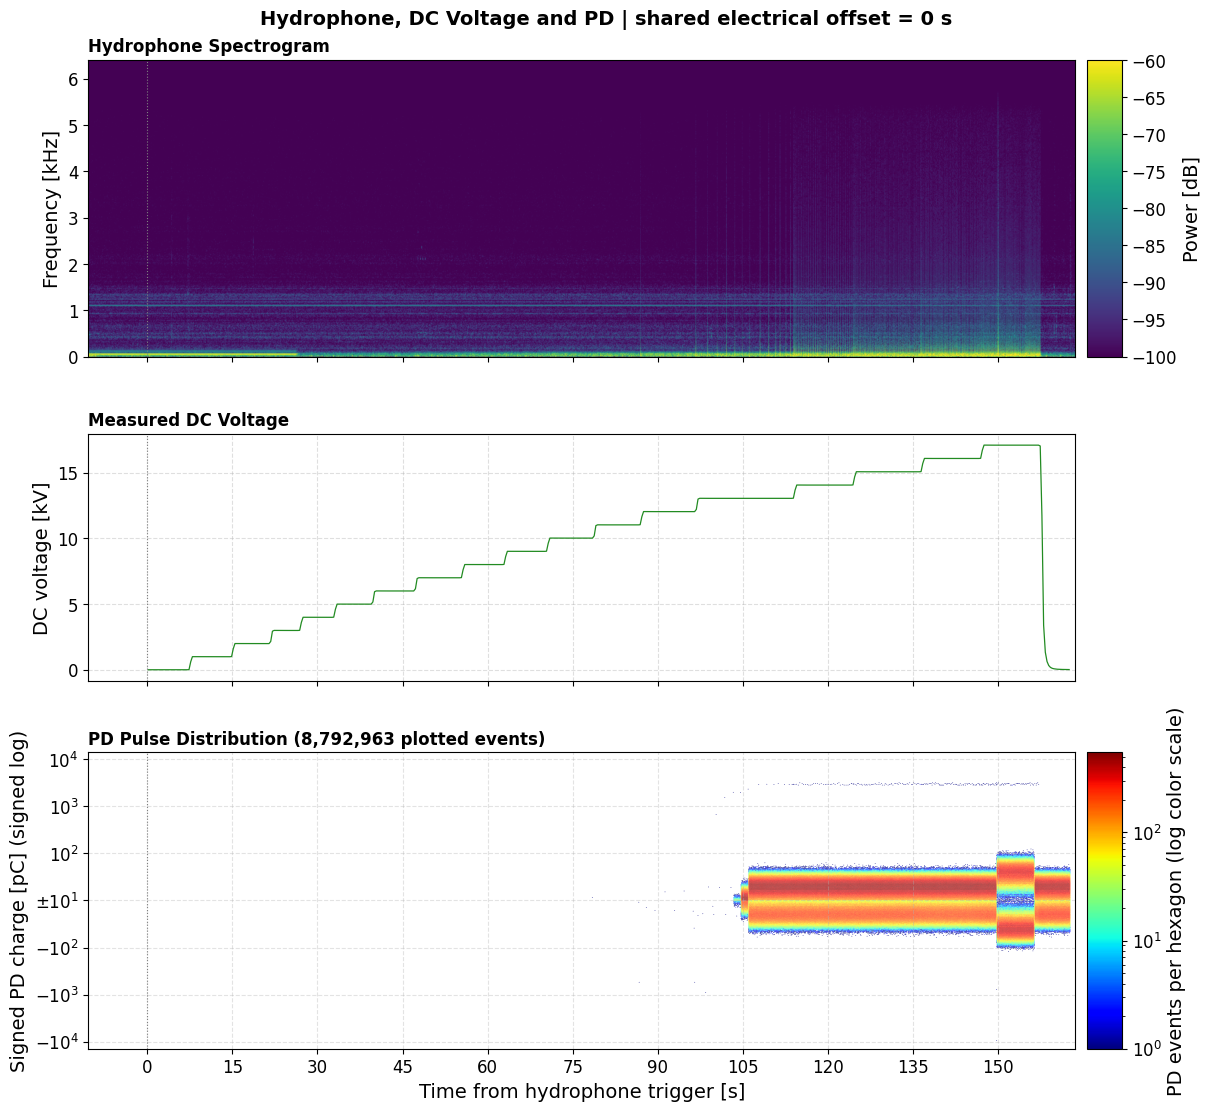

In [34]:
hydrophone_dc_pd_combined_fig = plot_dc_stacked_combined('hydrophone')
hydrophone_dc_pd_combined_path = save_figure(
    hydrophone_dc_pd_combined_fig,
    figure_suffix('Hydrophone_Spectrogram_DC_Voltage_PD_Combined',
                  trimmed_lvm_data, trimmed_ae_data, include_hydro_spec=True)
    + f'_shift{_filename_value(manual_DC_time_adjust)}s',
    category='combined', dpi=figure_dpi,
)
plt.show()


Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\combined\PD-acoustic-EMPIRE_147_AE_Spectrogram_DC_Voltage_PD_Combined_t-10p387-163p564s_aeSpec_200k_-145to-110dB_shift0s.png


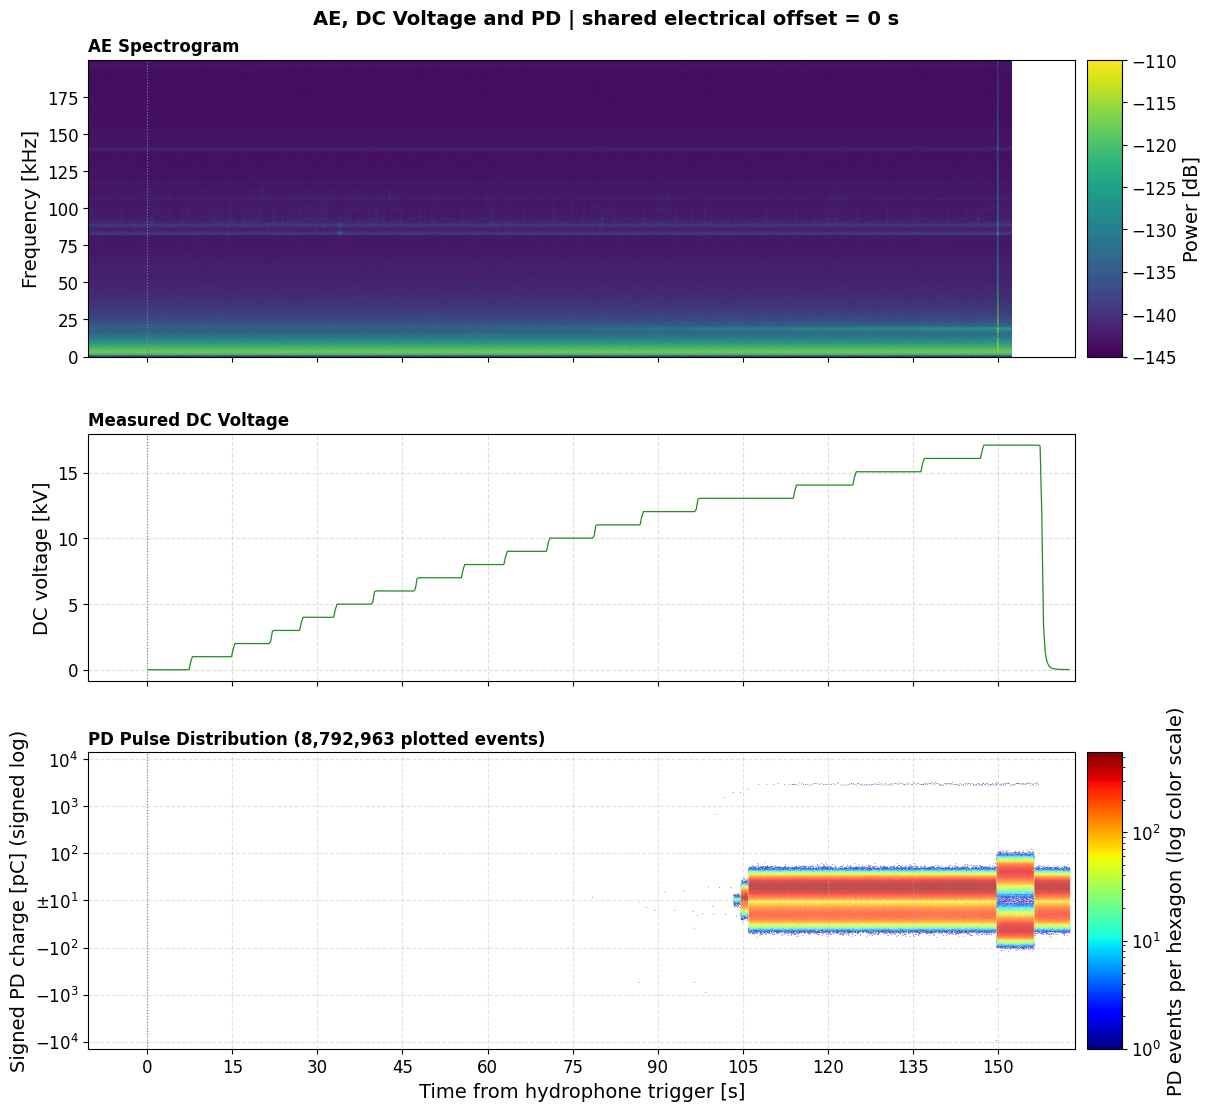

In [35]:
ae_dc_pd_combined_fig = plot_dc_stacked_combined('ae')
ae_dc_pd_combined_path = save_figure(
    ae_dc_pd_combined_fig,
    figure_suffix('AE_Spectrogram_DC_Voltage_PD_Combined',
                  trimmed_lvm_data, trimmed_ae_data, include_ae_spec=True)
    + f'_shift{_filename_value(manual_DC_time_adjust)}s',
    category='combined', dpi=figure_dpi, includes_ae=True,
)
plt.show()


### Generate Hydrophone-Only Plot

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Unfiltered_Hydrophone_Spectrogram_t-10p387-163p564s_hydSpec_12k_-100to-60dB.png


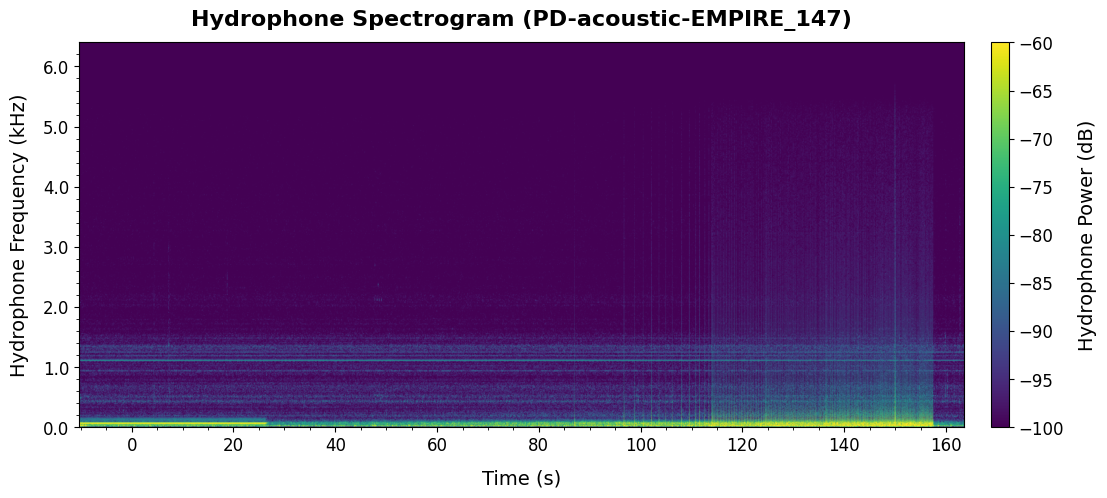

In [36]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.98, 0.02],   # relative widths for plots, colorbar
    height_ratios=[1],
    hspace=0.10,                 # Small vertical gap between plots
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])              # Left: Hydrophone spectrogram
cax1 = fig.add_subplot(gs[0, 1])              # Right: Hydrophone colorbar axis (aligned with spectrogram)

# --- Plot Hydrophone Spectrogram ---
im1 = ax1.imshow(
    hydrophone_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_sync_times[0],
        hydrophone_sync_times[-1],
        hydrophone_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax1.set_title(f'Hydrophone Spectrogram ({lvm_stem})', fontsize=16, pad=12, fontweight='bold')
ax1.set_xlabel('Time (s)', fontsize=label_size, labelpad=10)
ax1.set_ylabel('Hydrophone Frequency (kHz)', fontsize=label_size, labelpad=10)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax1.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach hydrophone colorbar to the narrower cax1 axis
cbar = fig.colorbar(im1, cax=cax1, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size, labelpad=10)
cbar.ax.tick_params(labelsize=tick_size)

save_figure(fig, figure_suffix("Unfiltered_Hydrophone_Spectrogram", trimmed_lvm_data, include_hydro_spec=True), category="hydrophone_only", dpi=figure_dpi)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\hydrophone_only\PD-acoustic-EMPIRE_147_Filtered_Hydrophone_Spectrogram_t-10p387-163p564s_hp60Hz_hydSpec_12k_-100to-60dB.png


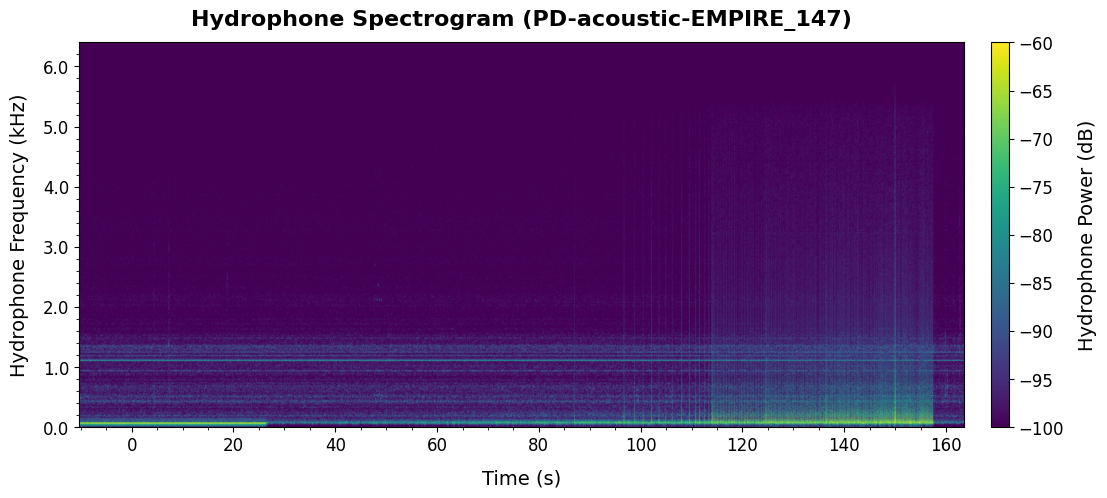

In [37]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.98, 0.02],   # relative widths for plots, colorbar
    height_ratios=[1],
    hspace=0.10,                 # Small vertical gap between plots
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])              # Left: Hydrophone spectrogram
cax1 = fig.add_subplot(gs[0, 1])              # Right: Hydrophone colorbar axis (aligned with spectrogram)

# --- Plot Hydrophone Spectrogram ---
im1 = ax1.imshow(
    hydrophone_hp_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_hp_sync_times[0],
        hydrophone_hp_sync_times[-1],
        hydrophone_hp_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_hp_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax1.set_title(f'Hydrophone Spectrogram ({lvm_stem})', fontsize=16, pad=12, fontweight='bold')
ax1.set_xlabel('Time (s)', fontsize=label_size, labelpad=10)
ax1.set_ylabel('Hydrophone Frequency (kHz)', fontsize=label_size, labelpad=10)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax1.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach hydrophone colorbar to the narrower cax1 axis
cbar = fig.colorbar(im1, cax=cax1, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size, labelpad=10)
cbar.ax.tick_params(labelsize=tick_size)

hp_hydrophone_spectrogram_path = save_figure(fig, figure_suffix("Filtered_Hydrophone_Spectrogram", trimmed_high_pass_lvm_data, include_cutoff=True, include_hydro_spec=True), category="hydrophone_only", dpi=figure_dpi)
plt.show()

### Generate AE-Only Plot

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\ae_only\PD-acoustic-EMPIRE_147_AE_Spectrogram_t-10p387-152p532s_aeSpec_200k_-145to-110dB.png


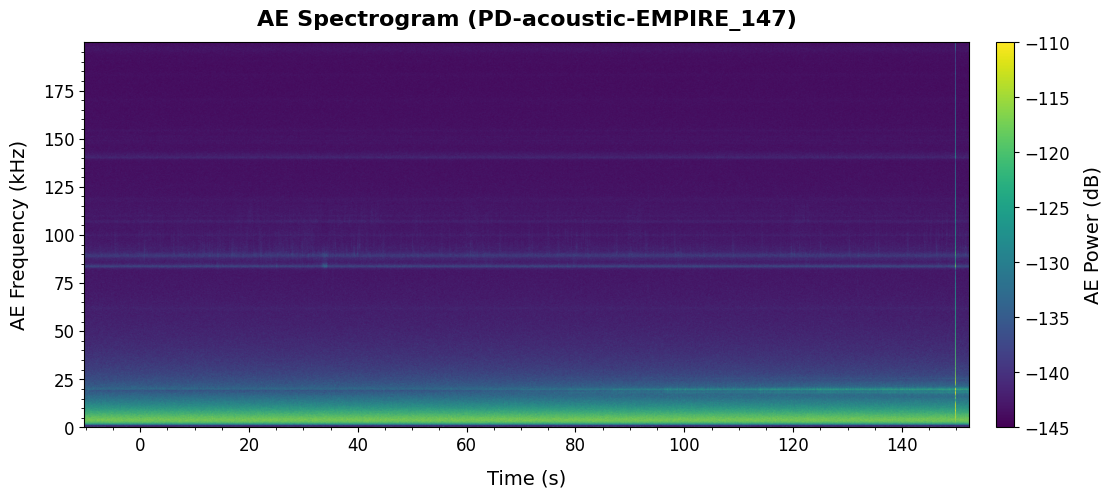

In [38]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 5))
gs = fig.add_gridspec(
    nrows=1,
    ncols=2,
    width_ratios=[0.98, 0.02],   # relative widths for plots, colorbar
    height_ratios=[1],
    hspace=0.10,                 # Small vertical gap between plots
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])              # Left: AE spectrogram
cax1 = fig.add_subplot(gs[0, 1])              # Right: AE colorbar axis (aligned with spectrogram)

# --- Plot AE Spectrogram ---
im1 = ax1.imshow(
    ae_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        ae_sync_times[0],
        ae_sync_times[-1],
        ae_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        ae_masked_frequencies[-1] / 1e3
    ],
    vmin=min_ae_spectrogram_value_ctrl,
    vmax=max_ae_spectrogram_value_ctrl,
    cmap=ae_cmap,
    interpolation='bilinear'
)
ax1.set_title(f'AE Spectrogram ({lvm_stem})', fontsize=16, pad=12, fontweight='bold')
ax1.set_xlabel('Time (s)', fontsize=label_size, labelpad=10)
ax1.set_ylabel('AE Frequency (kHz)', fontsize=label_size, labelpad=10)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))
ax1.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach AE colorbar to the narrower cax1 axis
cbar = fig.colorbar(im1, cax=cax1, orientation='vertical')
cbar.set_label('AE Power (dB)', fontsize=label_size, labelpad=10)
cbar.ax.tick_params(labelsize=tick_size)

ae_spectrogram_path = save_figure(fig, figure_suffix("AE_Spectrogram", trimmed_ae_data, include_ae_spec=True), category="ae_only", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_AE_UnfilteredHydrophone_Spectrogram_t-10p387-163p564s_aeSpec_200k_-145to-110dB_hydSpec_12k_-100to-60dB.png


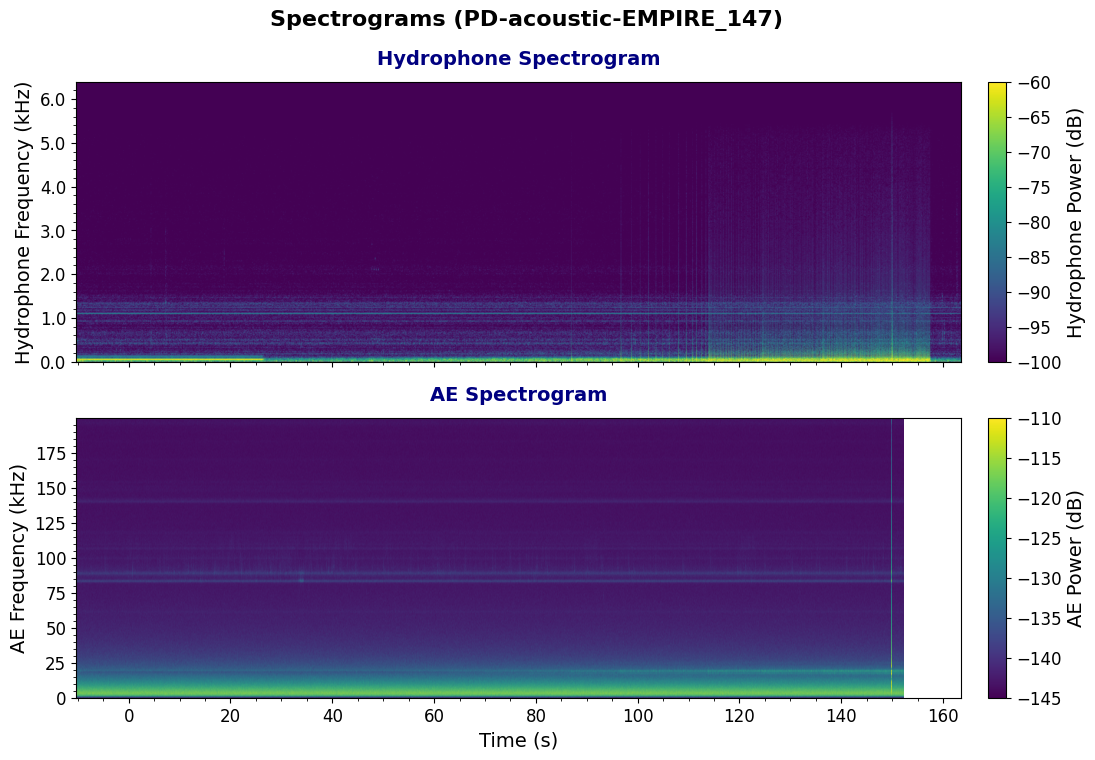

In [39]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[0.98, 0.02],   # relative widths for plots, colorbar
    height_ratios=[1,1],
    hspace=0.20,
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])              # Top-left: Hydrophone spectrogram
cax1 = fig.add_subplot(gs[0, 1])              # Top-right: Hydrophone colorbar axis (aligned with spectrogram)
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)              # Bottom-left: AE spectrogram
cax2 = fig.add_subplot(gs[1, 1])             # Bottom-right: AE colorbar axis (aligned with spectrogram)

# --- Plot Hydrophone Spectrogram ---
im1 = ax1.imshow(
    hydrophone_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_sync_times[0],
        hydrophone_sync_times[-1],
        hydrophone_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax1.set_title('Hydrophone Spectrogram', fontsize=label_size, pad=12, fontweight='bold', color='navy')
ax1.set_ylabel('Hydrophone Frequency (kHz)', fontsize=label_size)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax1.tick_params(axis='y', which='major', labelsize=tick_size)
ax1.tick_params(axis='x', labelbottom=False)

# Attach hydrophone colorbar to the narrower cax1 axis
cbar = fig.colorbar(im1, cax=cax1, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

# --- Plot AE Spectrogram ---
im2 = ax2.imshow(
    ae_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        ae_sync_times[0],
        ae_sync_times[-1],
        ae_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        ae_masked_frequencies[-1] / 1e3
    ],
    vmin=min_ae_spectrogram_value_ctrl,
    vmax=max_ae_spectrogram_value_ctrl,
    cmap=ae_cmap,
    interpolation='bilinear'
)
ax2.set_title('AE Spectrogram', fontsize=label_size, pad=12, fontweight='bold', color='navy')
ax2.set_xlabel('Time (s)', fontsize=label_size)
ax2.set_ylabel('AE Frequency (kHz)', fontsize=label_size)
ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))
ax2.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach AE colorbar to the narrower cax2 axis
cbar = fig.colorbar(im2, cax=cax2, orientation='vertical')
cbar.set_label('AE Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

if plot_full_spectrogram_extent:
    full_time_start = min(hydrophone_sync_times[0], ae_sync_times[0])
    full_time_end = max(hydrophone_sync_times[-1], ae_sync_times[-1])
    ax1.set_xlim(full_time_start, full_time_end)

fig.suptitle(
    f"Spectrograms ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.97
)

save_figure(fig, figure_suffix("AE_UnfilteredHydrophone_Spectrogram", trimmed_lvm_data, trimmed_ae_data, include_ae_spec=True, include_hydro_spec=True), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comparative\PD-acoustic-EMPIRE_147_AE_FilteredHydrophone_Spectrogram_t-10p387-163p564s_hp60Hz_aeSpec_200k_-145to-110dB_hydSpec_12k_-100to-60dB.png


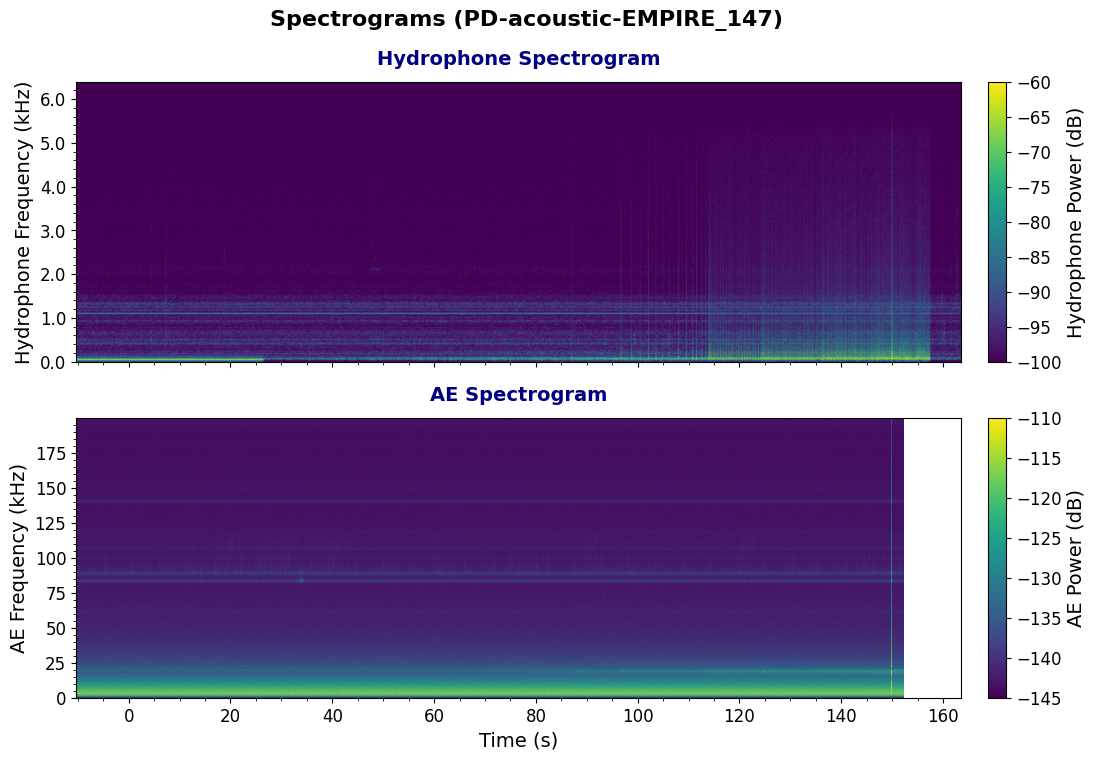

In [40]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    width_ratios=[0.98, 0.02],   # relative widths for plots, colorbar
    height_ratios=[1,1],
    hspace=0.20,
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])              # Top-left: Hydrophone spectrogram
cax1 = fig.add_subplot(gs[0, 1])              # Top-right: Hydrophone colorbar axis (aligned with spectrogram)
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)              # Bottom-left: AE spectrogram
cax2 = fig.add_subplot(gs[1, 1])             # Bottom-right: AE colorbar axis (aligned with spectrogram)

# --- Plot Hydrophone Spectrogram ---
im1 = ax1.imshow(
    hydrophone_hp_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_sync_times[0],
        hydrophone_sync_times[-1],
        hydrophone_hp_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_hp_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax1.set_title('Hydrophone Spectrogram', fontsize=label_size, pad=12, fontweight='bold', color='navy')
ax1.set_ylabel('Hydrophone Frequency (kHz)', fontsize=label_size)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax1.tick_params(axis='y', which='major', labelsize=tick_size)
ax1.tick_params(axis='x', labelbottom=False)

# Attach hydrophone colorbar to the narrower cax1 axis
cbar = fig.colorbar(im1, cax=cax1, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

# --- Plot AE Spectrogram ---
im2 = ax2.imshow(
    ae_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        ae_sync_times[0],
        ae_sync_times[-1],
        ae_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        ae_masked_frequencies[-1] / 1e3
    ],
    vmin=min_ae_spectrogram_value_ctrl,
    vmax=max_ae_spectrogram_value_ctrl,
    cmap=ae_cmap,
    interpolation='bilinear'
)
ax2.set_title('AE Spectrogram', fontsize=label_size, pad=12, fontweight='bold', color='navy')
ax2.set_xlabel('Time (s)', fontsize=label_size)
ax2.set_ylabel('AE Frequency (kHz)', fontsize=label_size)
ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))
ax2.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach AE colorbar to the narrower cax2 axis
cbar = fig.colorbar(im2, cax=cax2, orientation='vertical')
cbar.set_label('AE Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

if plot_full_spectrogram_extent:
    full_time_start = min(hydrophone_hp_sync_times[0], ae_sync_times[0])
    full_time_end = max(hydrophone_hp_sync_times[-1], ae_sync_times[-1])
    ax1.set_xlim(full_time_start, full_time_end)

fig.suptitle(
    f"Spectrograms ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.97
)

hp_ae_spectrogram_comparative_path = save_figure(fig, figure_suffix("AE_FilteredHydrophone_Spectrogram", trimmed_high_pass_lvm_data, trimmed_ae_data, include_cutoff=True, include_ae_spec=True, include_hydro_spec=True), category="comparative", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comprehensive\PD-acoustic-EMPIRE_147_AE_Signal_RMS_Spectrogram_t-10p387-152p532s_aeSpec_200k_-145to-110dB.png


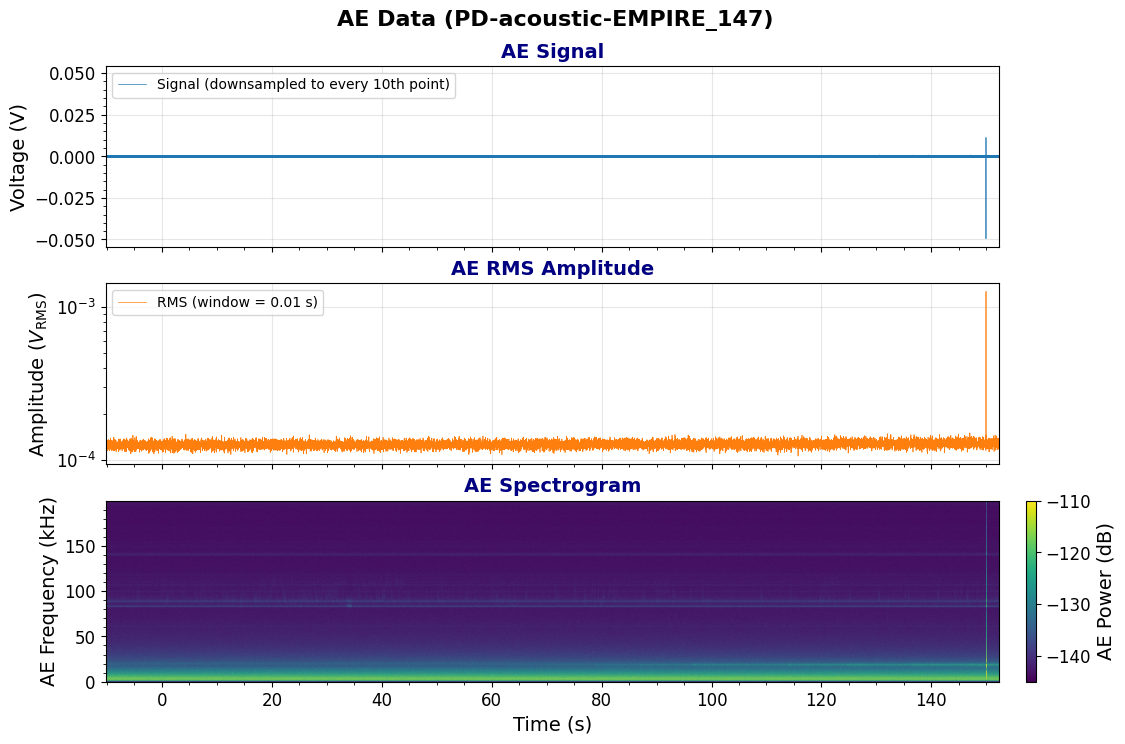

In [41]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    width_ratios=[0.98, 0.01],   # relative widths for plots, colorbar
    height_ratios=[1,1,1],
    hspace=0.20,
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])                          # Top-left: AE signal line plot
# cax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)              # Middle-left: AE Amplitude line plot
# cax2 = fig.add_subplot(gs[1, 1])
ax3 = fig.add_subplot(gs[2, 0], sharex=ax1)              # Bottom-left: AE Spectrogram
cax3 = fig.add_subplot(gs[2, 1])                         # Bottom-right: AE Spectrogram colorbar axis

# --- Plot AE Line Plot ---
ae_step = 10  # Plot every nth point to reduce rendering time; adjust as needed for performance vs. visual density
x_ds = trimmed_ae_data[::ae_step, 0]
y_ds = trimmed_ae_data[::ae_step, 1]

if ae_step == 1:
    label = "Signal"
else:
    if ae_step % 100 in (11, 12, 13):  # Special case for 11th, 12th, 13th
        suffix = "th"
    elif ae_step % 10 == 1:
        suffix = "st"
    elif ae_step % 10 == 2:
        suffix = "nd"
    elif ae_step % 10 == 3:
        suffix = "rd"
    else:
        suffix = "th"
    label = f"Signal (downsampled to every {ae_step}{suffix} point)"

ax1.plot(x_ds, y_ds, color='tab:blue', linewidth=0.5, label=label)
abs_max = np.max(np.abs(y_ds))
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.set_ylim(-abs_max*1.1, abs_max*1.1)
ax1.set_title('AE Signal', fontsize=label_size, fontweight='bold', color='navy')
ax1.set_ylabel('Voltage (V)', fontsize=label_size)
ax1.tick_params(axis='y', which='major', labelsize=tick_size)
ax1.tick_params(axis='x', labelbottom=False)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# --- Plot AE Amplitude (RMS) Line Plot ---
ax2.plot(ae_rms_times, ae_rms_values, color='tab:orange', linewidth=0.5, label=f"RMS (window = {ae_window_duration} s)")
ax2.set_title(f'AE RMS Amplitude', fontsize=label_size, fontweight='bold', color='navy')
ax2.set_yscale("log")
# ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.set_ylabel('RMS Amplitude (V)', fontsize=label_size)
ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax2.tick_params(axis='y', which='major', labelsize=tick_size)
ax2.tick_params(axis='x', labelbottom=False)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper left')

# --- Plot AE Spectrogram ---
im = ax3.imshow(
    ae_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        ae_sync_times[0],
        ae_sync_times[-1],
        ae_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        ae_masked_frequencies[-1] / 1e3
    ],
    vmin=min_ae_spectrogram_value_ctrl,
    vmax=max_ae_spectrogram_value_ctrl,
    cmap=ae_cmap,
    interpolation='bilinear'
)
ax3.set_title('AE Spectrogram', fontsize=label_size, fontweight='bold', color='navy')
ax3.yaxis.set_minor_locator(AutoMinorLocator())
ax3.set_xlabel('Time (s)', fontsize=label_size)
ax3.set_ylabel('AE Frequency (kHz)', fontsize=label_size)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}'))
ax3.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach AE colorbar to the narrower cax3 axis
cbar = fig.colorbar(im, cax=cax3, orientation='vertical')
cbar.set_label('AE Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

fig.suptitle(
    f"AE Data ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.95
)

ae_comprehensive_path = save_figure(fig, figure_suffix("AE_Signal_RMS_Spectrogram", trimmed_ae_data, include_ae_spec=True), category="comprehensive", dpi=figure_dpi, includes_ae=True)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comprehensive\PD-acoustic-EMPIRE_147_Hydrophone_Signal_RMS_Spectrogram_t-10p387-163p564s_hydSpec_12k_-100to-60dB.png


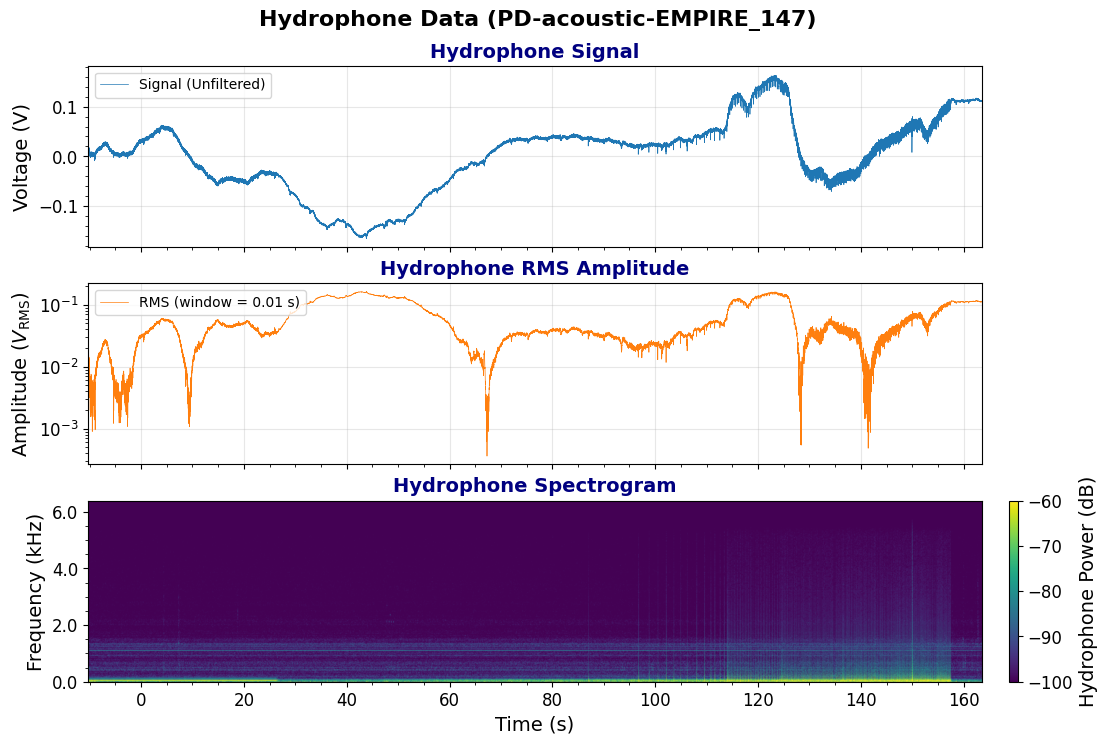

In [42]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    width_ratios=[0.98, 0.01],   # relative widths for plots, colorbar
    height_ratios=[1,1,1],
    hspace=0.20,
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])                          # Top-left: Hydrophone signal line plot
# cax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)              # Middle-left: Hydrophone RMS Amplitude line plot
# cax2 = fig.add_subplot(gs[1, 1])
ax3 = fig.add_subplot(gs[2, 0], sharex=ax1)              # Bottom-left: Hydrophone Spectrogram
cax3 = fig.add_subplot(gs[2, 1])                         # Bottom-right: Hydrophone Spectrogram colorbar axis

# --- Plot Hydrophone Line Plot ---
ax1.plot(trimmed_lvm_data[:, 0], trimmed_lvm_data[:, 1], color='tab:blue', linewidth=0.5, label=f'Signal (Unfiltered)')
abs_max = np.max(np.abs(trimmed_lvm_data[:, 1]))
ax1.set_ylim(-abs_max*1.1, abs_max*1.1)
ax1.set_title('Hydrophone Signal', fontsize=label_size, fontweight='bold', color='navy')
ax1.set_ylabel('Voltage (V)', fontsize=label_size)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis='y', which='major', labelsize=tick_size)
ax1.tick_params(axis='x', labelbottom=False)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# --- Plot Hydrophone Amplitude (RMS) Line Plot ---
ax2.plot(hydrophone_rms_times, hydrophone_rms_values, color='tab:orange', linewidth=0.5, label=f"RMS (window = {hydrophone_window_duration} s)")
ax2.set_title(f'Hydrophone RMS Amplitude', fontsize=label_size, fontweight='bold', color='navy')
ax2.set_yscale("log")
# ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax2.tick_params(axis='y', which='major', labelsize=tick_size)
ax2.tick_params(axis='x', labelbottom=False)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# --- Plot Hydrophone Spectrogram ---
im = ax3.imshow(
    hydrophone_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_sync_times[0],
        hydrophone_sync_times[-1],
        hydrophone_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax3.set_title('Hydrophone Spectrogram', fontsize=label_size, fontweight='bold', color='navy')
ax3.set_xlabel('Time (s)', fontsize=label_size)
ax3.set_ylabel('Frequency (kHz)', fontsize=label_size)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax3.yaxis.set_minor_locator(AutoMinorLocator())
ax3.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach Hydrophone colorbar to the narrower cax3 axis
cbar = fig.colorbar(im, cax=cax3, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

fig.suptitle(
    f"Hydrophone Data ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.95
)

suffix = figure_suffix(
    "Hydrophone_Signal_RMS_Spectrogram",
    trimmed_lvm_data,
    include_hydro_spec=True,
)
save_figure(fig, suffix, category="comprehensive", dpi=figure_dpi)
plt.show()

Saved figure: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\imgs\comprehensive\PD-acoustic-EMPIRE_147_Filtered_Hydrophone_Signal_RMS_Spectrogram_t-10p387-163p564s_hp60Hz_hydSpec_12k_-100to-60dB.png


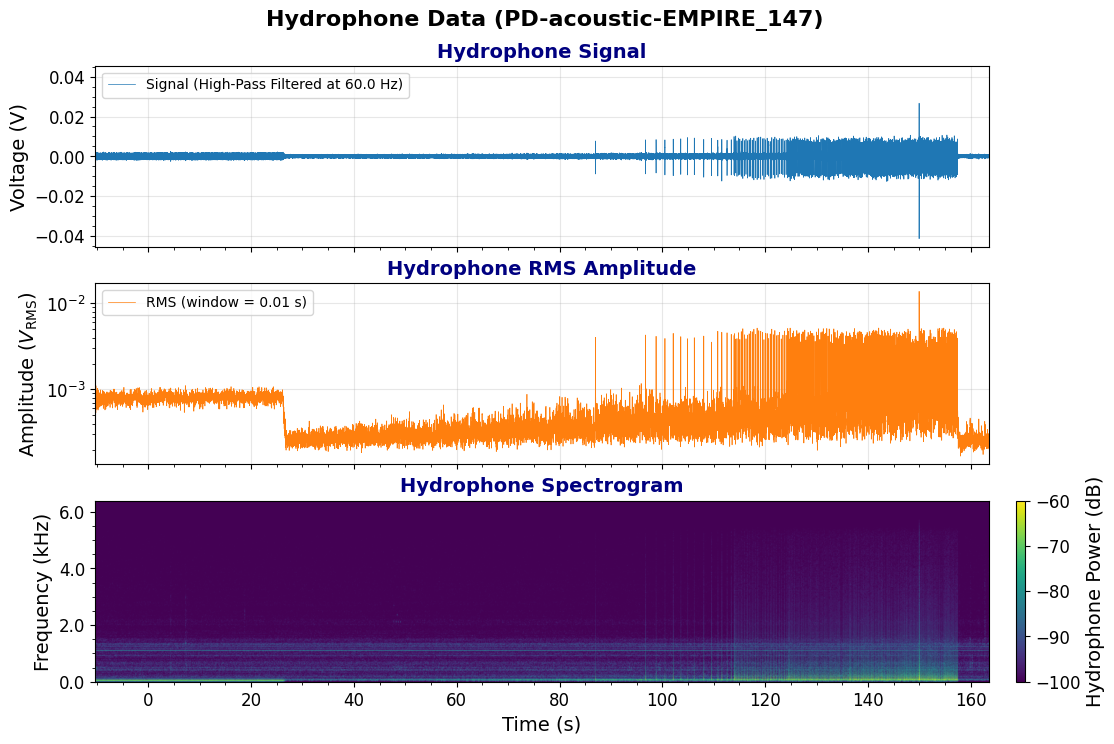

In [43]:
# Create a figure and GridSpec layout: left column for plots, right column for a narrower colorbar
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    width_ratios=[0.98, 0.01],   # relative widths for plots, colorbar
    height_ratios=[1,1,1],
    hspace=0.20,
    wspace=0.06                  # Small horizontal gap between plots and colorbar
)

ax1 = fig.add_subplot(gs[0, 0])                          # Top-left: Hydrophone signal line plot
# cax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, 0], sharex=ax1)              # Middle-left: Hydrophone RMS Amplitude line plot
# cax2 = fig.add_subplot(gs[1, 1])
ax3 = fig.add_subplot(gs[2, 0], sharex=ax1)              # Bottom-left: Hydrophone Spectrogram
cax3 = fig.add_subplot(gs[2, 1])                         # Bottom-right: Hydrophone Spectrogram colorbar axis

# --- Plot Hydrophone Line Plot ---
ax1.plot(trimmed_high_pass_lvm_data[:, 0], trimmed_high_pass_lvm_data[:, 1], color='tab:blue', linewidth=0.5, label=f'Signal (High-Pass Filtered at {cutoff_freq} Hz)')
abs_max = np.max(np.abs(trimmed_high_pass_lvm_data[:, 1]))
ax1.set_ylim(-abs_max*1.1, abs_max*1.1)
ax1.set_title('Hydrophone Signal', fontsize=label_size, fontweight='bold', color='navy')
ax1.set_ylabel('Voltage (V)', fontsize=label_size)
ax1.xaxis.set_major_locator(MaxNLocator(nbins=15, steps=[1, 2, 2.5, 5, 10]))
ax1.xaxis.set_minor_locator(AutoMinorLocator())
ax1.yaxis.set_minor_locator(AutoMinorLocator())
ax1.tick_params(axis='y', which='major', labelsize=tick_size)
ax1.tick_params(axis='x', labelbottom=False)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# --- Plot Filtered Hydrophone Amplitude (RMS) Line Plot ---
ax2.plot(hydrophone_rms_times_hp, hydrophone_rms_values_hp, color='tab:orange', linewidth=0.5, label=f"RMS (window = {hydrophone_window_duration} s)")
ax2.set_title(f'Hydrophone RMS Amplitude', fontsize=label_size, fontweight='bold', color='navy')
ax2.set_yscale("log")
# ax2.yaxis.set_minor_locator(AutoMinorLocator())
ax2.set_ylabel(r"Amplitude ($V_{\mathrm{RMS}}$)", fontsize=label_size)
ax2.tick_params(axis='y', which='major', labelsize=tick_size)
ax2.tick_params(axis='x', labelbottom=False)
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# --- Plot Filtered Hydrophone Spectrogram ---
im = ax3.imshow(
    hydrophone_hp_masked_Sxx_log,
    aspect='auto',
    origin='lower',
    extent=[
        hydrophone_hp_sync_times[0],
        hydrophone_hp_sync_times[-1],
        hydrophone_hp_masked_frequencies[0] / 1e3,  # Convert to kHz for y-axis
        hydrophone_hp_masked_frequencies[-1] / 1e3
    ],
    vmin=min_hydro_spectrogram_value_ctrl,
    vmax=max_hydro_spectrogram_value_ctrl,
    cmap=hydro_cmap,
    interpolation='bilinear'
)
ax3.set_title('Hydrophone Spectrogram', fontsize=label_size, fontweight='bold', color='navy')
ax3.set_xlabel('Time (s)', fontsize=label_size)
ax3.set_ylabel('Frequency (kHz)', fontsize=label_size)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.1f}'))
ax3.yaxis.set_minor_locator(AutoMinorLocator())
ax3.tick_params(axis='both', which='major', labelsize=tick_size)

# Attach Hydrophone colorbar to the narrower cax3 axis
cbar = fig.colorbar(im, cax=cax3, orientation='vertical')
cbar.set_label('Hydrophone Power (dB)', fontsize=label_size)
cbar.ax.tick_params(labelsize=tick_size)

fig.suptitle(
    f"Hydrophone Data ({lvm_stem})", 
    fontsize=16, 
    fontweight='bold', 
    y=0.95
)

suffix = figure_suffix(
    "Filtered_Hydrophone_Signal_RMS_Spectrogram",
    trimmed_high_pass_lvm_data,
    include_cutoff=True,
    include_hydro_spec=True,
)
hp_hydrophone_comprehensive_path = save_figure(fig, suffix, category="comprehensive", dpi=figure_dpi)
plt.show()

# Create PowerPoint Slides

The optional export includes the three existing acoustic slides and one separate slide for each of the three combined figures. Run both stacked figure cells above before exporting the PowerPoint.


In [44]:
# Optional PowerPoint summary deck
make_powerpoint = input("Generate PowerPoint summary after saving plots? (y/n): ").strip().lower()

if make_powerpoint in {"y", "yes"}:
    try:
        from pptx import Presentation
        from pptx.enum.text import PP_ALIGN
        from pptx.util import Inches, Pt
        from PIL import Image
    except ImportError as exc:
        raise ImportError("Install python-pptx and Pillow to generate PowerPoint files: pip install python-pptx pillow") from exc

    pptx_dir = lvm_path.parent / "powerpoints"
    pptx_dir.mkdir(exist_ok=True)
    pptx_path = pptx_dir / f"{lvm_stem}_hydrophone_ae_summary.pptx"

    prs = Presentation()
    prs.slide_width = Inches(13.333)
    prs.slide_height = Inches(7.5)
    blank_layout = prs.slide_layouts[6]

    image_width = Inches(6.5)
    left_x = Inches(0.15)
    right_x = Inches(6.72)
    title_height = Inches(0.45)
    min_image_top = Inches(0.65)

    def image_height_at_width(image_path, width):
        with Image.open(image_path) as img:
            return int(width * img.height / img.width)

    def add_titled_slide(title):
        slide = prs.slides.add_slide(blank_layout)

        title_box = slide.shapes.add_textbox(Inches(0.25), Inches(0.12), Inches(12.83), title_height)
        title_frame = title_box.text_frame
        title_frame.clear()
        paragraph = title_frame.paragraphs[0]
        paragraph.alignment = PP_ALIGN.CENTER
        run = paragraph.add_run()
        run.text = f"{title} ({lvm_stem})"
        run.font.size = Pt(22)
        run.font.bold = True
        return slide

    def add_slide_with_images(title, left_image, right_image):
        slide = add_titled_slide(title)
        left_height = image_height_at_width(left_image, image_width)
        right_height = image_height_at_width(right_image, image_width)
        group_height = max(left_height, right_height)
        image_top = max(min_image_top, int((prs.slide_height - group_height) / 2))

        slide.shapes.add_picture(str(left_image), left_x, image_top, width=image_width)
        slide.shapes.add_picture(str(right_image), right_x, image_top, width=image_width)

    def add_slide_with_image(title, image_path):
        slide = add_titled_slide(title)
        with Image.open(image_path) as img:
            width_px, height_px = img.size

        # Fit both landscape and stacked figures beneath the title without cropping.
        available_width = prs.slide_width - Inches(0.5)
        available_height = prs.slide_height - min_image_top - Inches(0.15)
        scale = min(available_width / width_px, available_height / height_px)
        width = int(width_px * scale)
        height = int(height_px * scale)
        left = int((prs.slide_width - width) / 2)
        top = min_image_top + int((available_height - height) / 2)
        slide.shapes.add_picture(str(image_path), left, top, width=width, height=height)

    required_images = {
        "High-pass hydrophone comprehensive figure": hp_hydrophone_comprehensive_path,
        "AE comprehensive figure": ae_comprehensive_path,
        "High-pass hydrophone + AE amplitude comparative figure": hp_ae_amplitude_comparative_path,
        "High-pass hydrophone + AE spectrogram comparative figure": hp_ae_spectrogram_comparative_path,
        "High-pass hydrophone spectrogram": hp_hydrophone_spectrogram_path,
        "AE spectrogram": ae_spectrogram_path,
        "Hydrophone + AE + DC voltage + PD combined figure": dc_combined_path,
        "Hydrophone + DC voltage + PD stacked figure": hydrophone_dc_pd_combined_path,
        "AE + DC voltage + PD stacked figure": ae_dc_pd_combined_path,
    }
    missing_images = [name for name, path in required_images.items() if not Path(path).is_file()]
    if missing_images:
        raise FileNotFoundError("Missing images for PowerPoint: " + "; ".join(missing_images))

    add_slide_with_images(
        "Comprehensive Signals",
        hp_hydrophone_comprehensive_path,
        ae_comprehensive_path,
    )
    add_slide_with_images(
        "Comparative Amplitude and Spectrogram",
        hp_ae_amplitude_comparative_path,
        hp_ae_spectrogram_comparative_path,
    )
    add_slide_with_images(
        "Spectrogram Detail",
        hp_hydrophone_spectrogram_path,
        ae_spectrogram_path,
    )

    add_slide_with_image(
        "Hydrophone, AE, DC Voltage and PD",
        dc_combined_path,
    )
    add_slide_with_image(
        "Hydrophone, DC Voltage and PD",
        hydrophone_dc_pd_combined_path,
    )
    add_slide_with_image(
        "AE, DC Voltage and PD",
        ae_dc_pd_combined_path,
    )

    prs.save(pptx_path)
    print(f"Saved PowerPoint: {pptx_path}")
else:
    print("PowerPoint generation skipped.")


Saved PowerPoint: E:\AE_Data\PD-acoustic-EMPIRE-2026-10-02\PD-acoustic-EMPIRE_147\powerpoints\PD-acoustic-EMPIRE_147_hydrophone_ae_summary.pptx
